<a href="https://colab.research.google.com/github/mshitie/quantitative_XAI/blob/main/BUS_accuracy_vs_interpretability_multiobjective_BreastCancerOriginal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Accuracy vs. Interpretability in Breast Ultrasound: Multi-Objective Learning ("Breast Cancer Original" dataset)
Objectives: **(1)** diagnostic loss (CE) and **(2)** explanation loss (CAM / lesion-mask overlap).
Optimizers compared: weighted-sum (lambda sweep), MGDA, PCGrad, preference-conditioned Pareto model, NSGA-II (hyper-parameter level).
Extras: mask-dilation / loss ablations, faithfulness (deletion/insertion), sanity checks, shortcut (confounder) experiment, hypervolume, statistics.

> **Changed for the new dataset** (changed cells start with `# >>> CHANGED`): data is read from the Colab folder `Breast Cancer Original/{Benign,Malignant}` (image + `_mask` file per case, e.g. `malignant (232).png` / `malignant (232)_mask.png`) instead of Kaggle BUSI. The model code is unchanged: it was already binary (benign vs malignant).

**Runtime > Change runtime type > GPU (T4)** before running. Set `QUICK = True` in cell 2 for a fast smoke test.


In [6]:
# >>> CHANGED: ---------- 1. Install packages + locate the dataset (no Kaggle download) ----------
!pip install -q pymoo scikit-learn scipy seaborn
import os, zipfile

# Option A - dataset is in Google Drive: uncomment the next two lines to mount it.
# from google.colab import drive
# drive.mount('/content/drive')

# Option B - dataset is a .zip file: put its path here (leave "" if the folder is already unzipped).
ZIP_PATH = ""        # e.g. "/content/drive/MyDrive/Breast Cancer Original.zip" or "/content/Breast Cancer Original.zip"
if ZIP_PATH:
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall("/content/Breast Cancer Original")
    print("Unzipped to /content/Breast Cancer Original")

# Folder that CONTAINS the Benign and Malignant sub-folders. If this path is wrong, cell 4 searches /content automatically.
DATA_DIR = "/content/Breast Cancer Original"
for d in sorted(os.listdir("/content")): print("/content/" + d)


/content/.config
/content/Breast Cancer Original
/content/Breast Cancer Original.zip
/content/results
/content/sample_data


In [7]:
# ---------- 2. Imports + configuration ----------
import os, glob, random, copy, time, math, shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import spearmanr, wilcoxon
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='talk')

QUICK = False            # True = tiny smoke test (1 seed, 3 epochs)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
S = 224                  # image size
CFG = dict(
    BS=16, LR=3e-4, WD=1e-4, PRETRAINED=True,
    EPOCHS=3 if QUICK else 15,
    SEEDS=[0] if QUICK else [0, 1, 2],
    LAMBDAS=[0.1, 0.5, 1, 2, 5],               # weighted-sum sweep (lambda=0 -> baseline)
    PREF_GRID=[0.0, 0.17, 0.33, 0.5, 0.67, 0.83, 1.0],   # weight on explanation objective at inference
    RUN_NSGA2=True, NSGA_POP=4 if QUICK else 6, NSGA_GEN=2 if QUICK else 3, NSGA_EPOCHS=2 if QUICK else 6,
    RUN_CONFOUNDER=True,
    FAITH_N=60,
)
OUT = 'results'; FIG = f'{OUT}/figs'
os.makedirs(FIG, exist_ok=True)
print('device:', DEVICE, '| config:', CFG)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device: cuda | config: {'BS': 16, 'LR': 0.0003, 'WD': 0.0001, 'PRETRAINED': True, 'EPOCHS': 15, 'SEEDS': [0, 1, 2], 'LAMBDAS': [0.1, 0.5, 1, 2, 5], 'PREF_GRID': [0.0, 0.17, 0.33, 0.5, 0.67, 0.83, 1.0], 'RUN_NSGA2': True, 'NSGA_POP': 6, 'NSGA_GEN': 3, 'NSGA_EPOCHS': 6, 'RUN_CONFOUNDER': True, 'FAITH_N': 60}


DATA_DIR = /content/Breast Cancer Original/Breast Cancer Original
0 images skipped because no mask file was found
label
benign       361
malignant    253
Name: count, dtype: int64
usable images: 614
{'Xtr': (429, 1, 224, 224), 'Xva': (92, 1, 224, 224), 'Xte': (93, 1, 224, 224)}


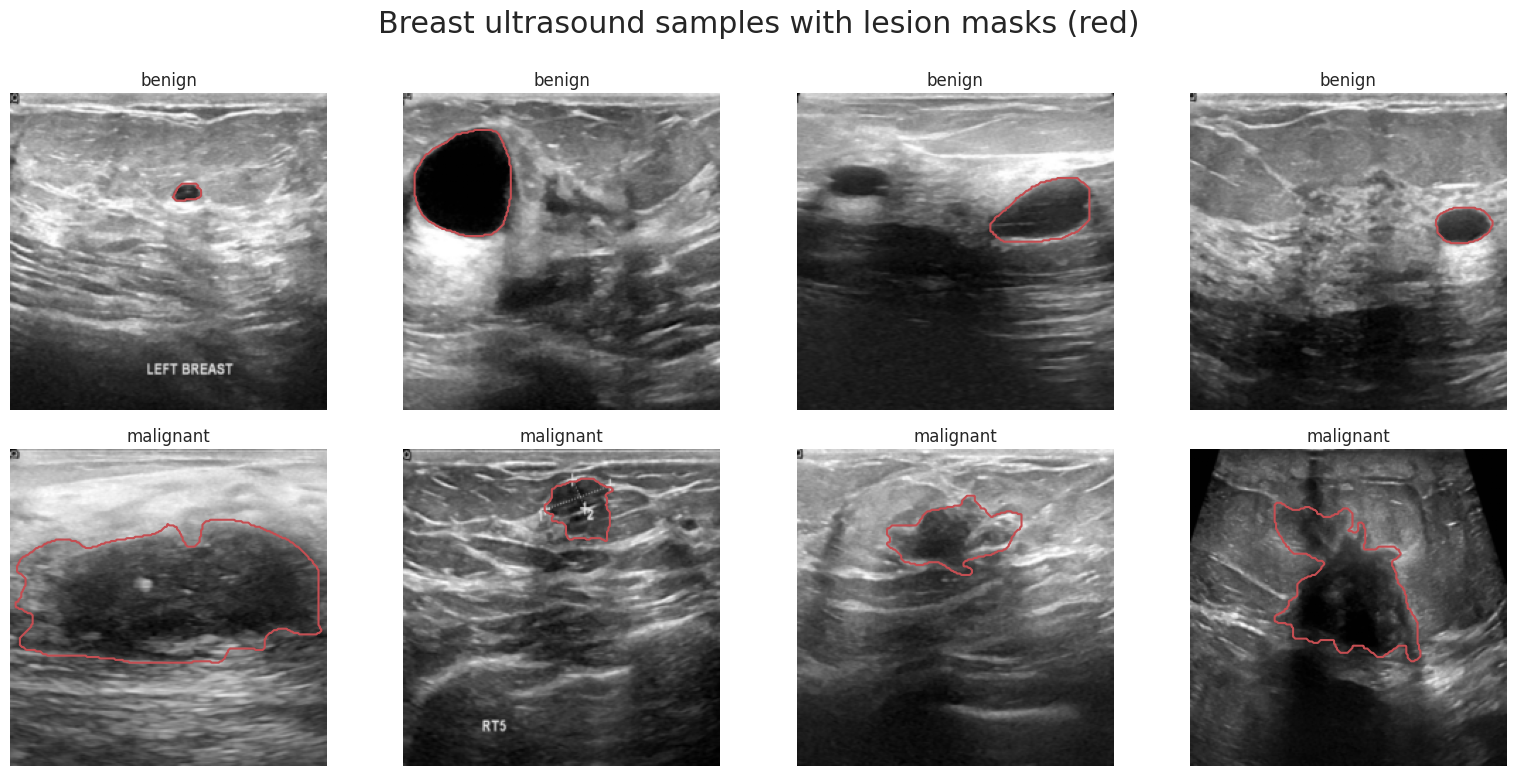

In [8]:
# ---------- 3. Build dataframe (benign vs malignant; masks merged) ----------
# >>> CHANGED: read Benign/Malignant folders (any letter case) of the "Breast Cancer Original" dataset
def find_data_dir(start='/content'):
    """First folder under `start` that has both a 'benign' and a 'malignant' sub-folder (case-insensitive)."""
    for root, dirs, _ in os.walk(start):
        dirs[:] = [d for d in dirs if d not in ('sample_data', '.config', '__pycache__')]
        low = {d.lower() for d in dirs}
        if 'benign' in low and 'malignant' in low: return root
    return None

if not os.path.isdir(DATA_DIR) or not {d.lower() for d in os.listdir(DATA_DIR)} >= {'benign', 'malignant'}:
    DATA_DIR = find_data_dir('/content')
    assert DATA_DIR, 'No folder with Benign/ and Malignant/ sub-folders found under /content - set DATA_DIR by hand (cell 2).'
print('DATA_DIR =', DATA_DIR)
FOLDER = {c: d for c in ['benign', 'malignant'] for d in os.listdir(DATA_DIR) if d.lower() == c}
IMG_EXT = ('.png', '.jpg', '.jpeg', '.bmp')

rows, n_nomask = [], 0
for cls in ['benign', 'malignant']:
    folder = os.path.join(DATA_DIR, FOLDER[cls])
    for f in sorted(glob.glob(os.path.join(glob.escape(folder), '*'))):
        stem, ext = os.path.splitext(os.path.basename(f))
        if ext.lower() not in IMG_EXT or '_mask' in stem.lower(): continue
        masks = [m for m in glob.glob(glob.escape(os.path.join(folder, stem)) + '_mask*')
                 if os.path.splitext(m)[1].lower() in IMG_EXT]
        if len(masks): rows.append(dict(path=f, label=int(cls == 'malignant'), masks=masks))
        else: n_nomask += 1                                   # no mask -> cannot be used (explanation loss needs it)
print(f'{n_nomask} images skipped because no mask file was found')
df = pd.DataFrame(rows)
print(df.label.value_counts().rename({0: 'benign', 1: 'malignant'}))

def load_item(r):
    img = np.array(Image.open(r.path).convert('L').resize((S, S), Image.BILINEAR))
    m = np.zeros((S, S), np.float32)
    for mp in r.masks:
        mk = np.array(Image.open(mp).convert('L').resize((S, S), Image.NEAREST))
        m = np.maximum(m, (mk > 0.5 * max(mk.max(), 1)).astype(np.float32))      # >>> CHANGED: works for 0/255 and 0/1 masks
    return img, m

items = [load_item(r) for r in df.itertuples()]
X_all = torch.from_numpy(np.stack([i[0] for i in items]))[:, None]           # uint8 (N,1,S,S)
M_all = torch.from_numpy(np.stack([i[1] for i in items]))[:, None]           # float (N,1,S,S)
y_all = torch.tensor(df.label.values)
keep = M_all.flatten(1).sum(1) > 0
X_all, M_all, y_all = X_all[keep], M_all[keep], y_all[keep]
N = len(y_all); print('usable images:', N)

# fixed stratified split 70/15/15 (same test set for every run)
idx = np.arange(N)
i_tr, i_tmp = train_test_split(idx, test_size=0.30, stratify=y_all.numpy(), random_state=42)
i_va, i_te = train_test_split(i_tmp, test_size=0.50, stratify=y_all.numpy()[i_tmp], random_state=42)
def make_data(X, M, y):
    d = {}
    for k, ii in [('tr', i_tr), ('va', i_va), ('te', i_te)]:
        d['X' + k], d['M' + k], d['y' + k] = X[ii].to(DEVICE), M[ii].to(DEVICE), y[ii].to(DEVICE)
    return d
DATA = make_data(X_all, M_all, y_all)
print({k: tuple(v.shape) for k, v in DATA.items() if k.startswith('X')})

# dataset overview figure
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for c in range(2):
    sel = np.where(y_all.numpy() == c)[0][:4]
    for j, s in enumerate(sel):
        ax[c, j].imshow(X_all[s, 0], cmap='gray'); ax[c, j].contour(M_all[s, 0], [0.5], colors='r', linewidths=1.5)
        ax[c, j].set_title(['benign', 'malignant'][c], fontsize=12); ax[c, j].axis('off')
plt.suptitle('Breast ultrasound samples with lesion masks (red)'); plt.tight_layout()
plt.savefig(f'{FIG}/00_dataset_samples.png', dpi=200); plt.show()

In [9]:
# ---------- 4. Model, differentiable CAM, losses, GPU augmentation ----------
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
def prep(x01):                                  # x01: (B,1,S,S) in [0,1]
    return (x01.repeat(1, 3, 1, 1) - MEAN) / STD

class Net(nn.Module):
    """ResNet-18 + GAP + FC. For GAP->FC nets, Grad-CAM at the last conv layer == CAM (up to a constant),
    so we train with the closed-form CAM (no second-order gradients). cond=True adds FiLM conditioning on a
    preference vector (Pareto-front learning: one model, many trade-offs)."""
    def __init__(self, cond=False):
        super().__init__()
        r = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT if CFG['PRETRAINED'] else None)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4)
        self.fc = nn.Linear(512, 2); self.cond = cond
        if cond:
            self.film = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 1024))
            nn.init.zeros_(self.film[-1].weight); nn.init.zeros_(self.film[-1].bias)
    def forward(self, x, pref=None):
        f = self.stem(x)
        if self.cond:
            g, b = self.film(pref).chunk(2, 1)
            f = f * (1 + g[:, :, None, None]) + b[:, :, None, None]
        return self.fc(f.mean((2, 3))), f

def cam_raw(f, W, cls):                          # class-specific CAM at feature resolution
    return (f * W[cls][:, :, None, None]).sum(1, keepdim=True)
def up(c): return F.interpolate(c, size=(S, S), mode='bilinear', align_corners=False)
def norm_cam(c):
    c = F.relu(c); return c / (c.flatten(1).amax(1)[:, None, None, None] + 1e-6)

def exp_loss(cam, m, kind='dice'):
    inter = (cam * m).flatten(1).sum(1)
    if kind == 'dice':                           # 1 - soft Dice(CAM, mask)
        return (1 - (2 * inter + 1) / (cam.flatten(1).sum(1) + m.flatten(1).sum(1) + 1)).mean()
    return (1 - inter / (cam.flatten(1).sum(1) + 1e-6)).mean()   # 'energy': CAM mass outside mask (RRR-style)

def dilate(m, px):                               # peri-lesional band (radiologists use surrounding tissue)
    return m if px <= 0 else F.max_pool2d(m, 2 * px + 1, 1, px)

def augment(x, m):
    B, dev = x.size(0), x.device
    r = lambda: torch.rand(B, device=dev) * 2 - 1
    ang, sc = r() * 10 * math.pi / 180, 1 + r() * 0.1
    tx, ty = r() * 0.1, r() * 0.1
    flip = (torch.rand(B, device=dev) < 0.5).float() * 2 - 1
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c * flip, -s, tx], 1), torch.stack([s * flip, c, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)
    m = (F.grid_sample(m, grid, padding_mode='zeros', align_corners=False) > 0.5).float()
    x = (x * (1 + r().view(B, 1, 1, 1) * 0.2) + r().view(B, 1, 1, 1) * 0.1).clamp(0, 1)
    return x, m

# ---- gradient helpers for MGDA / PCGrad ----
def flat_grads(loss, params):
    gs = torch.autograd.grad(loss, params, retain_graph=True, allow_unused=True)
    return torch.cat([(g if g is not None else torch.zeros_like(p)).reshape(-1) for g, p in zip(gs, params)])
def set_grads(params, g):
    o = 0
    for p in params:
        n = p.numel(); p.grad = g[o:o + n].view_as(p).clone(); o += n
def mgda_alpha(gc, ge):                          # closed-form min-norm point for 2 objectives
    a = ((ge - gc) @ ge) / (((gc - ge) ** 2).sum() + 1e-12)
    return a.clamp(0, 1)
def pcgrad(gc, ge):
    gs, orig = [gc.clone(), ge.clone()], [gc, ge]
    order = [0, 1]; random.shuffle(order)
    for i in order:
        j = 1 - i; d = gs[i] @ orig[j]
        if d < 0: gs[i] -= d / (orig[j] @ orig[j] + 1e-12) * orig[j]
    return gs[0] + gs[1]

In [10]:
# ---------- 5. Prediction, metrics, faithfulness, sanity checks ----------
def _pref(pref, B):
    return None if pref is None else torch.tensor(pref, device=DEVICE, dtype=torch.float32)[None].expand(B, 2)

@torch.no_grad()
def predict(model, X, pref=None, bs=64):
    model.eval(); P, C = [], []
    for i in range(0, len(X), bs):
        x = prep(X[i:i + bs].float() / 255)
        logits, f = model(x, _pref(pref, len(x)))
        pr = F.softmax(logits, 1)
        C.append(norm_cam(up(cam_raw(f, model.fc.weight, pr.argmax(1))))); P.append(pr)
    return torch.cat(P), torch.cat(C)           # predicted-class CAMs

def ece_bins(conf, correct, nb=10):
    edges = np.linspace(0.5, 1.0, nb + 1); b = np.clip(np.digitize(conf, edges[1:-1]), 0, nb - 1)
    acc = np.array([correct[b == k].mean() if (b == k).any() else np.nan for k in range(nb)])
    cf = np.array([conf[b == k].mean() if (b == k).any() else np.nan for k in range(nb)])
    cnt = np.array([(b == k).sum() for k in range(nb)])
    ece = np.nansum(np.abs(acc - cf) * cnt / len(conf))
    return ece, cf, acc, cnt

def compute_metrics(probs, y, cams, M):
    p1, yn = probs[:, 1].cpu().numpy(), y.cpu().numpy(); pred = (p1 >= 0.5).astype(int)
    tp, tn = ((pred == 1) & (yn == 1)).sum(), ((pred == 0) & (yn == 0)).sum()
    fp, fn = ((pred == 1) & (yn == 0)).sum(), ((pred == 0) & (yn == 1)).sum()
    sens, spec = tp / max(tp + fn, 1), tn / max(tn + fp, 1)
    f1 = 2 * tp / max(2 * tp + fp + fn, 1)
    conf = np.maximum(p1, 1 - p1); ece = ece_bins(conf, (pred == yn).astype(float))[0]
    cb = (cams >= 0.5).float()
    inter = (cb * M).flatten(1).sum(1); union = ((cb + M) > 0).float().flatten(1).sum(1)
    iou = inter / union.clamp(min=1)
    dice = 2 * inter / (cb.flatten(1).sum(1) + M.flatten(1).sum(1)).clamp(min=1)
    energy = (cams * M).flatten(1).sum(1) / cams.flatten(1).sum(1).clamp(min=1e-6)
    am = cams.flatten(1).argmax(1); point = M.flatten(1).gather(1, am[:, None])[:, 0]
    out = dict(auc=roc_auc_score(yn, p1), acc=(pred == yn).mean(), sens=sens, spec=spec, f1=f1, ece=ece,
               brier=float(((p1 - yn) ** 2).mean()), iou=iou.mean().item(), dice=dice.mean().item(),
               energy=energy.mean().item(), point=point.mean().item())
    return out, iou.cpu().numpy()

def _trapz(y, x): return float(np.sum((y[1:] + y[:-1]) / 2 * np.diff(x)))

@torch.no_grad()
def faithfulness(model, X, probs, cams, pref=None, n=60, patch=16):
    """Deletion (lower=better) / insertion (higher=better) AUC of predicted-class probability."""
    n = min(n, len(X)); x = prep(X[:n].float() / 255); pc = probs[:n].argmax(1)
    g = F.avg_pool2d(cams[:n], patch).flatten(1); P = g.shape[1]
    rank = g.argsort(1, descending=True).argsort(1)
    blur = F.avg_pool2d(F.pad(x, (10, 10, 10, 10), mode='reflect'), 21, 1)
    fr = np.linspace(0, 1, 15); dl, ins = [], []
    pr_ = _pref(pref, n)
    for f in fr:
        k = int(round(f * P))
        keepm = F.interpolate((rank < k).float().view(n, 1, S // patch, S // patch), scale_factor=patch, mode='nearest')
        pd_ = F.softmax(model(x * (1 - keepm), pr_)[0], 1)[torch.arange(n), pc]
        pi_ = F.softmax(model(blur * (1 - keepm) + x * keepm, pr_)[0], 1)[torch.arange(n), pc]
        dl.append(pd_.mean().item()); ins.append(pi_.mean().item())
    return _trapz(np.array(dl), fr), _trapz(np.array(ins), fr)

def randomization_check(model, X, pref=None, n=50):
    """Adebayo-style sanity check: re-initialise layer4 + fc; CAMs should change (low |Spearman|)."""
    m2 = copy.deepcopy(model)
    for mod in [m2.stem[7], m2.fc]:
        for l in mod.modules():
            if hasattr(l, 'reset_parameters'): l.reset_parameters()
    _, c1 = predict(model, X[:n], pref); _, c2 = predict(m2, X[:n], pref)
    a, b = F.avg_pool2d(c1, 16).flatten(1).cpu().numpy(), F.avg_pool2d(c2, 16).flatten(1).cpu().numpy()
    rho = [abs(spearmanr(a[i], b[i])[0]) for i in range(len(a)) if a[i].std() > 0 and b[i].std() > 0]
    return float(np.nanmean(rho))

def gradcam_equivalence(model, X, n=16):
    """Verify true Grad-CAM (autograd) == closed-form CAM used in training."""
    model.eval(); x = prep(X[:n].float() / 255)
    with torch.enable_grad():
        logits, f = model(x); pc = logits.argmax(1)
        g = torch.autograd.grad(logits[torch.arange(len(x)), pc].sum(), f)[0]
        gc = F.relu((g.mean((2, 3), keepdim=True) * f).sum(1, keepdim=True)).detach()
    cc = F.relu(cam_raw(f, model.fc.weight, pc)).detach()
    a, b = gc.flatten(1), cc.flatten(1)
    return F.cosine_similarity(a, b, dim=1).mean().item()

In [11]:
# ---------- 6. Training (weighted-sum, MGDA, PCGrad, preference-conditioned) ----------
def train_run(method, lam, dil, kind, seed, data, epochs=None, lr=None, verbose=False):
    """method: 'ws' (loss=Lc+lam*Le; lam=0 -> baseline) | 'mgda' | 'pcgrad' | 'pref'."""
    epochs = epochs or CFG['EPOCHS']; lr = lr or CFG['LR']
    set_seed(seed)
    model = Net(cond=(method == 'pref')).to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=CFG['WD'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    ntr = len(data['ytr']); cnt = torch.bincount(data['ytr'], minlength=2).float()
    cw = (ntr / (2 * cnt)).to(DEVICE); hist = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(ntr, device=DEVICE); acc = dict(Lc=[], Le=[], cos=[], alpha=[])
        for i in range(0, ntr, CFG['BS']):
            idx = perm[i:i + CFG['BS']]
            if len(idx) < 4: continue
            x, m = augment(data['Xtr'][idx].float() / 255, data['Mtr'][idx]); y = data['ytr'][idx]
            r = None
            if method == 'pref':
                r = torch.distributions.Dirichlet(torch.ones(2)).sample().to(DEVICE)
            logits, f = model(prep(x), None if r is None else r[None].expand(len(idx), 2))
            Lc = F.cross_entropy(logits, y, weight=cw)
            cam = norm_cam(up(cam_raw(f, model.fc.weight, y)))      # CAM of the true class
            Le = exp_loss(cam, dilate(m, dil), kind)
            if method == 'ws':
                loss = Lc + lam * Le; opt.zero_grad(); loss.backward()
            elif method == 'pref':
                loss = r[0] * Lc + r[1] * Le; opt.zero_grad(); loss.backward()
            else:
                gc, ge = flat_grads(Lc, params), flat_grads(Le, params)
                acc['cos'].append(F.cosine_similarity(gc, ge, dim=0).item())
                if method == 'mgda':
                    a = mgda_alpha(gc, ge); g = a * gc + (1 - a) * ge; acc['alpha'].append(a.item())
                else:
                    g = pcgrad(gc, ge)
                opt.zero_grad(); set_grads(params, g)
            torch.nn.utils.clip_grad_norm_(params, 5.0); opt.step()
            acc['Lc'].append(Lc.item()); acc['Le'].append(Le.item())
        sched.step()
        vp = [0.5, 0.5] if method == 'pref' else None
        pv, cv = predict(model, data['Xva'], vp); mv, _ = compute_metrics(pv, data['yva'], cv, data['Mva'])
        h = dict(ep=ep + 1, Lc=np.mean(acc['Lc']), Le=np.mean(acc['Le']), val_auc=mv['auc'], val_iou=mv['iou'],
                 cos=np.mean(acc['cos']) if acc['cos'] else np.nan, alpha=np.mean(acc['alpha']) if acc['alpha'] else np.nan)
        hist.append(h)
        if verbose: print({k: round(v, 4) for k, v in h.items()})
    return model, pd.DataFrame(hist)

# quick sanity: one short run, verifying CAM == Grad-CAM
t0 = time.time()
_m, _h = train_run('ws', 1.0, 0, 'dice', 0, DATA, epochs=2, verbose=True)
print('Grad-CAM vs closed-form CAM cosine:', round(gradcam_equivalence(_m, DATA['Xte']), 4), f'| {time.time() - t0:.0f}s for 2 epochs')
del _m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 161MB/s]


{'ep': 1, 'Lc': np.float64(0.475), 'Le': np.float64(0.6805), 'val_auc': np.float64(0.9374), 'val_iou': 0.3261, 'cos': nan, 'alpha': nan}
{'ep': 2, 'Lc': np.float64(0.2944), 'Le': np.float64(0.5993), 'val_auc': np.float64(0.9635), 'val_iou': 0.4205, 'cos': nan, 'alpha': nan}
Grad-CAM vs closed-form CAM cosine: 1.0 | 6s for 2 epochs


In [12]:
# ---------- 7. Main experiment grid ----------
# (name, method, lambda, dilation_px, exp_loss_kind, family)
EXPS = [('baseline', 'ws', 0.0, 0, 'dice', 'WS')]
EXPS += [(f'ws_l{l:g}', 'ws', l, 0, 'dice', 'WS') for l in CFG['LAMBDAS']]
EXPS += [('mgda', 'mgda', 1, 0, 'dice', 'MGDA'), ('pcgrad', 'pcgrad', 1, 0, 'dice', 'PCGrad'),
         ('pref', 'pref', 1, 0, 'dice', 'PrefCond'),
         ('ws_l1_dil8', 'ws', 1.0, 8, 'dice', 'Ablation'), ('ws_l1_dil16', 'ws', 1.0, 16, 'dice', 'Ablation'),
         ('ws_l1_energy', 'ws', 1.0, 0, 'energy', 'Ablation')]
MAIN = ['baseline', 'ws_l1', 'mgda', 'pcgrad', 'pref_r0.50']

rows, HIST, PER_IMG, PROBS, MODELS = [], {}, {}, {}, {}
def add_row(name, fam, seed, model, pref=None, data=DATA, tag=''):
    probs, cams = predict(model, data['Xte'], pref)
    m, iou_i = compute_metrics(probs, data['yte'], cams, data['Mte'])
    d_auc, i_auc = faithfulness(model, data['Xte'], probs, cams, pref, CFG['FAITH_N'])
    m.update(name=name, family=fam, seed=seed, del_auc=d_auc, ins_auc=i_auc, tag=tag)
    rows.append(m); PER_IMG[(name, seed)] = iou_i; PROBS[(name, seed)] = probs.cpu().numpy()

T0 = time.time()
for seed in CFG['SEEDS']:
    for (name, method, lam, dil, kind, fam) in EXPS:
        model, hist = train_run(method, lam, dil, kind, seed, DATA)
        HIST[(name, seed)] = hist
        if method == 'pref':
            for rr in CFG['PREF_GRID']:
                add_row(f'pref_r{rr:.2f}', fam, seed, model, pref=[1 - rr, rr])
        else:
            add_row(name, fam, seed, model)
        if seed == CFG['SEEDS'][0]: MODELS[name] = model
        else: del model
        print(f'[seed {seed}] {name:14s} done | {time.time() - T0:.0f}s | last val AUC={hist.val_auc.iloc[-1]:.3f} val IoU={hist.val_iou.iloc[-1]:.3f}')
        torch.cuda.empty_cache()
RES = pd.DataFrame(rows); RES.to_csv(f'{OUT}/all_runs_test_metrics.csv', index=False)
print(RES.groupby('name')[['auc', 'iou']].mean().round(3).T)

[seed 0] baseline       done | 25s | last val AUC=0.981 val IoU=0.244
[seed 0] ws_l0.1        done | 53s | last val AUC=0.983 val IoU=0.415
[seed 0] ws_l0.5        done | 79s | last val AUC=0.982 val IoU=0.481
[seed 0] ws_l1          done | 106s | last val AUC=0.979 val IoU=0.493
[seed 0] ws_l2          done | 132s | last val AUC=0.979 val IoU=0.522
[seed 0] ws_l5          done | 158s | last val AUC=0.981 val IoU=0.533
[seed 0] mgda           done | 200s | last val AUC=0.980 val IoU=0.547
[seed 0] pcgrad         done | 243s | last val AUC=0.982 val IoU=0.511
[seed 0] pref           done | 279s | last val AUC=0.987 val IoU=0.488
[seed 0] ws_l1_dil8     done | 305s | last val AUC=0.975 val IoU=0.399
[seed 0] ws_l1_dil16    done | 333s | last val AUC=0.982 val IoU=0.304
[seed 0] ws_l1_energy   done | 359s | last val AUC=0.980 val IoU=0.047
[seed 1] baseline       done | 385s | last val AUC=0.981 val IoU=0.246
[seed 1] ws_l0.1        done | 411s | last val AUC=0.981 val IoU=0.374
[seed 1] 

auc            acc           sens  \
family   name                                                        
Ablation ws_l1_dil16   0.993 ± 0.003  0.961 ± 0.016  0.965 ± 0.015   
         ws_l1_dil8    0.995 ± 0.003  0.953 ± 0.012  0.947 ± 0.026   
         ws_l1_energy  0.994 ± 0.004  0.953 ± 0.027  0.939 ± 0.015   
MGDA     mgda          0.993 ± 0.002  0.939 ± 0.012   0.93 ± 0.055   
PCGrad   pcgrad        0.993 ± 0.003  0.943 ± 0.012    0.895 ± 0.0   
PrefCond pref_r0.00    0.992 ± 0.003  0.935 ± 0.022  0.947 ± 0.046   
         pref_r0.17    0.992 ± 0.003  0.939 ± 0.016  0.947 ± 0.046   
         pref_r0.33    0.992 ± 0.003  0.939 ± 0.016  0.947 ± 0.046   
         pref_r0.50    0.992 ± 0.003  0.935 ± 0.011  0.947 ± 0.046   
         pref_r0.67    0.991 ± 0.002  0.935 ± 0.011  0.947 ± 0.046   
         pref_r0.83    0.991 ± 0.002  0.932 ± 0.016  0.947 ± 0.046   
         pref_r1.00    0.991 ± 0.002  0.932 ± 0.016  0.947 ± 0.046   
WS       baseline      0.984 ± 0.008  0.946 ± 0.019   0.93 ± 0.015   
         ws_l0.1       0.993 ± 0.008  0.971 ± 0.006  0.974 ± 0.026   
         ws_l0.5       0.994 ± 0.006  0.961 ± 0.016   0.956 ± 0.04   
         ws_l1         0.995 ± 0.004  0.957 ± 0.011  0.947 ± 0.046   
         ws_l2         0.992 ± 0.005  0.961 ± 0.006   0.939 ± 0.04   
         ws_l5         0.992 ± 0.002  0.946 ± 0.022  0.956 ± 0.055   

                                spec             f1            ece  \
family   name                                                        
Ablation ws_l1_dil16   0.958 ± 0.021   0.952 ± 0.02  0.061 ± 0.008   
         ws_l1_dil8    0.958 ± 0.028  0.943 ± 0.015  0.047 ± 0.002   
         ws_l1_energy  0.964 ± 0.048  0.943 ± 0.031  0.051 ± 0.014   
MGDA     mgda          0.945 ± 0.018  0.925 ± 0.018  0.076 ± 0.004   
PCGrad   pcgrad        0.976 ± 0.021  0.927 ± 0.015  0.053 ± 0.007   
PrefCond pref_r0.00    0.927 ± 0.018  0.923 ± 0.026  0.047 ± 0.016   
         pref_r0.17     0.933 ± 0.01  0.927 ± 0.021   0.05 ± 0.004   
         pref_r0.33     0.933 ± 0.01  0.927 ± 0.021  0.043 ± 0.009   
         pref_r0.50    0.927 ± 0.018  0.923 ± 0.015  0.049 ± 0.001   
         pref_r0.67    0.927 ± 0.018  0.923 ± 0.015  0.046 ± 0.003   
         pref_r0.83    0.921 ± 0.021  0.919 ± 0.021  0.051 ± 0.009   
         pref_r1.00    0.921 ± 0.021  0.919 ± 0.021  0.051 ± 0.015   
WS       baseline      0.958 ± 0.028  0.934 ± 0.022  0.057 ± 0.012   
         ws_l0.1         0.97 ± 0.01  0.965 ± 0.008   0.05 ± 0.009   
         ws_l0.5       0.964 ± 0.048  0.952 ± 0.018   0.05 ± 0.014   
         ws_l1         0.964 ± 0.018  0.947 ± 0.014  0.045 ± 0.005   
         ws_l2         0.976 ± 0.028  0.951 ± 0.008  0.058 ± 0.002   
         ws_l5         0.939 ± 0.028  0.935 ± 0.027  0.058 ± 0.005   

                               brier            iou           dice  \
family   name                                                        
Ablation ws_l1_dil16   0.034 ± 0.008   0.33 ± 0.008  0.473 ± 0.011   
         ws_l1_dil8     0.026 ± 0.01  0.446 ± 0.004  0.592 ± 0.004   
         ws_l1_energy  0.032 ± 0.009  0.026 ± 0.003  0.047 ± 0.004   
MGDA     mgda          0.039 ± 0.003  0.553 ± 0.007  0.682 ± 0.009   
PCGrad   pcgrad        0.033 ± 0.001  0.515 ± 0.001  0.643 ± 0.001   
PrefCond pref_r0.00    0.041 ± 0.009  0.523 ± 0.012  0.652 ± 0.011   
         pref_r0.17    0.041 ± 0.009  0.524 ± 0.014  0.652 ± 0.012   
         pref_r0.33    0.042 ± 0.008  0.522 ± 0.015  0.651 ± 0.013   
         pref_r0.50    0.042 ± 0.008  0.518 ± 0.014  0.646 ± 0.011   
         pref_r0.67    0.042 ± 0.008  0.515 ± 0.015  0.644 ± 0.012   
         pref_r0.83    0.043 ± 0.008   0.51 ± 0.016  0.639 ± 0.014   
         pref_r1.00    0.043 ± 0.007   0.504 ± 0.02  0.632 ± 0.017   
WS       baseline      0.046 ± 0.013   0.241 ± 0.01   0.35 ± 0.014   
         ws_l0.1       0.029 ± 0.011  0.411 ± 0.029  0.543 ± 0.033   
         ws_l0.5       0.032 ± 0.016  0.495 ± 0.018  0.629 ± 0.019   
         ws_l1         0.027 ± 0.004  0.5

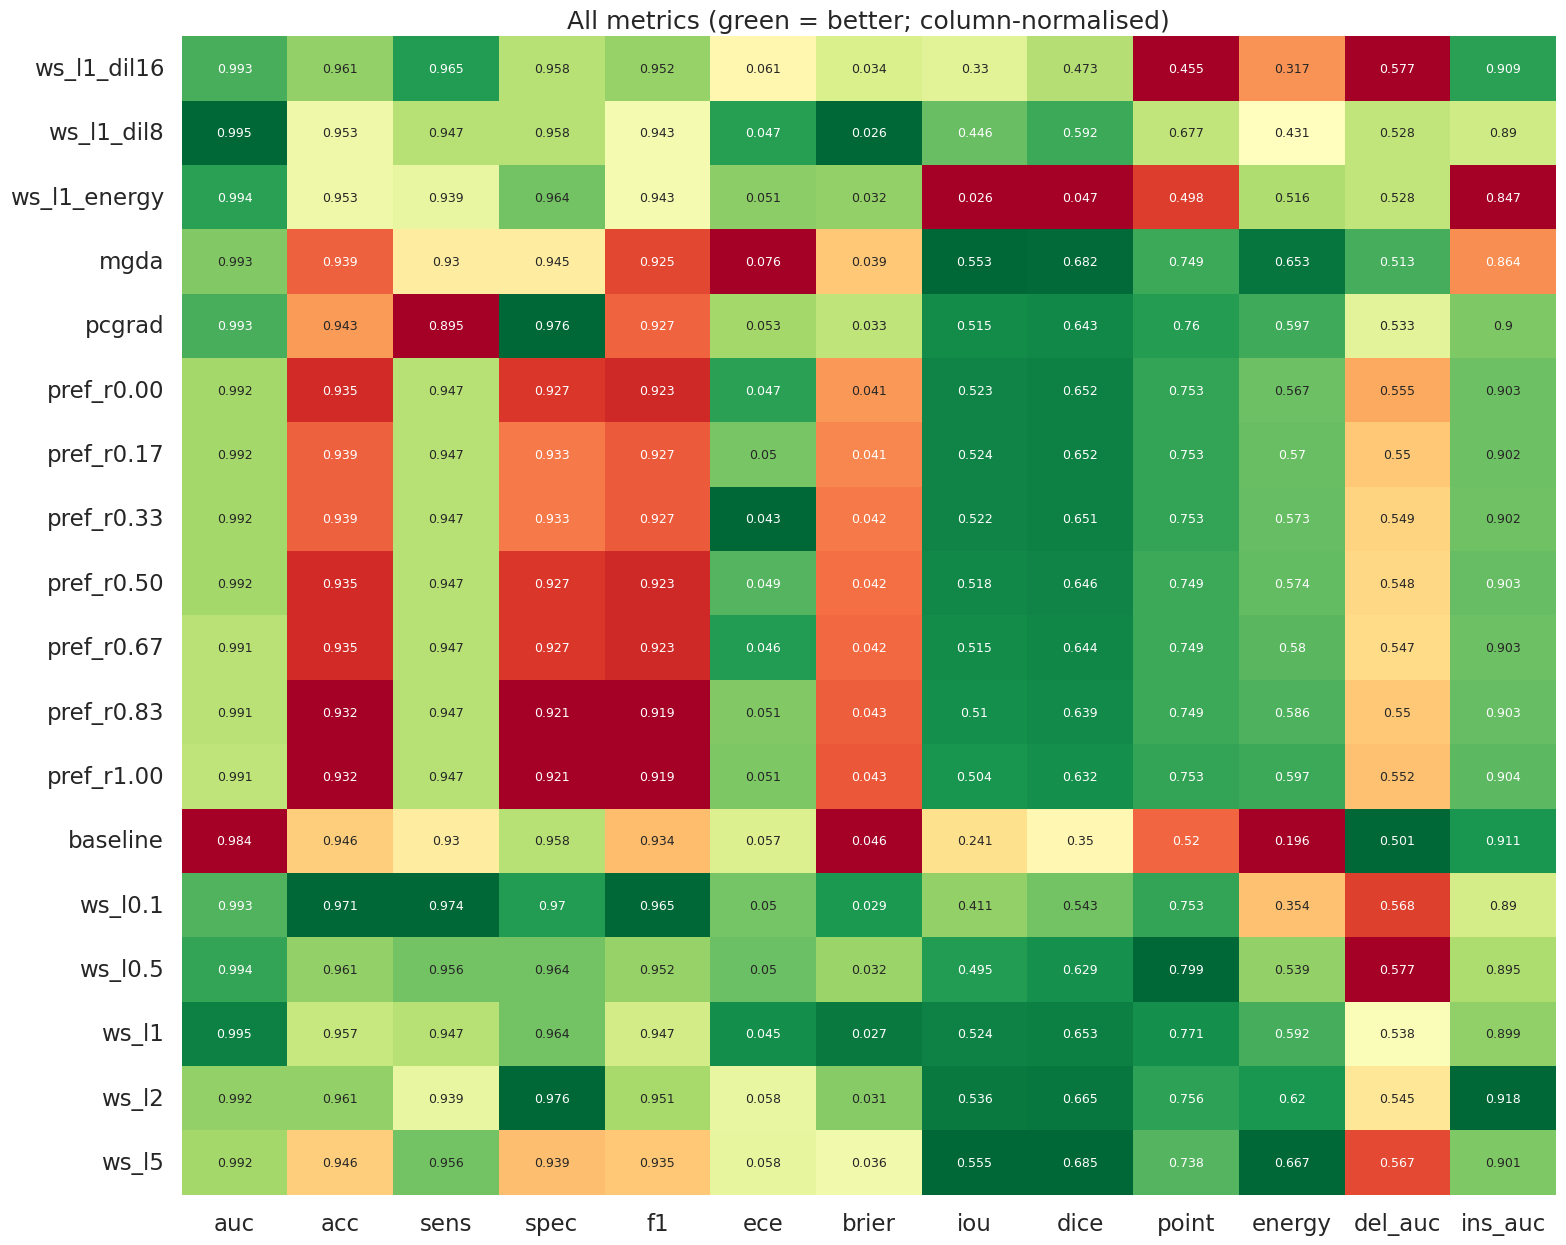

In [13]:
# ---------- 8. Summary table (mean +- std over seeds) ----------
cols = ['auc', 'acc', 'sens', 'spec', 'f1', 'ece', 'brier', 'iou', 'dice', 'point', 'energy', 'del_auc', 'ins_auc']
g = RES.groupby(['family', 'name'])[cols]
SUM = g.mean().round(3).astype(str) + ' ± ' + g.std().fillna(0).round(3).astype(str)
SUM.to_csv(f'{OUT}/summary_mean_std.csv'); display(SUM)
MEANS = RES.groupby(['family', 'name'])[cols].mean().reset_index()

fig, ax = plt.subplots(figsize=(16, 0.6 * len(MEANS) + 2))
hm = MEANS.set_index('name')[cols]; hmn = (hm - hm.min()) / (hm.max() - hm.min() + 1e-9)
for c in ['ece', 'brier', 'del_auc']: hmn[c] = 1 - hmn[c]          # lower is better -> flip colour
sns.heatmap(hmn, annot=hm.round(3), fmt='', cmap='RdYlGn', cbar=False, ax=ax, annot_kws={'size': 9})
ax.set_ylabel(''); ax.set_title('All metrics (green = better; column-normalised)')
plt.tight_layout(); plt.savefig(f'{FIG}/01_metrics_heatmap.png', dpi=200); plt.show()

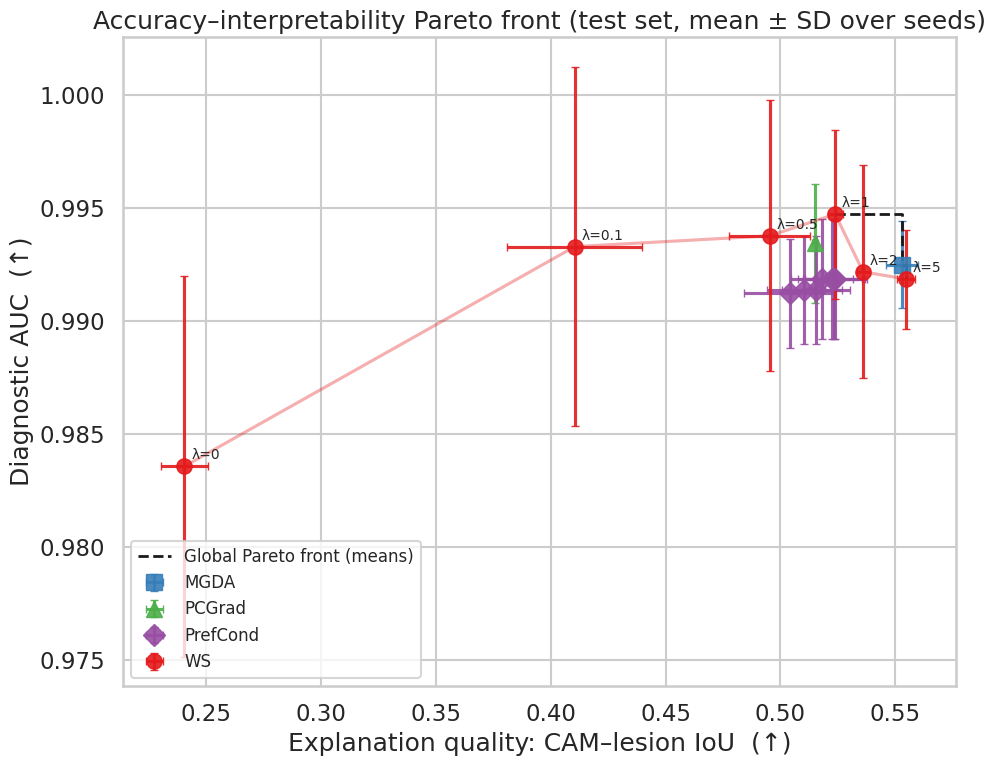

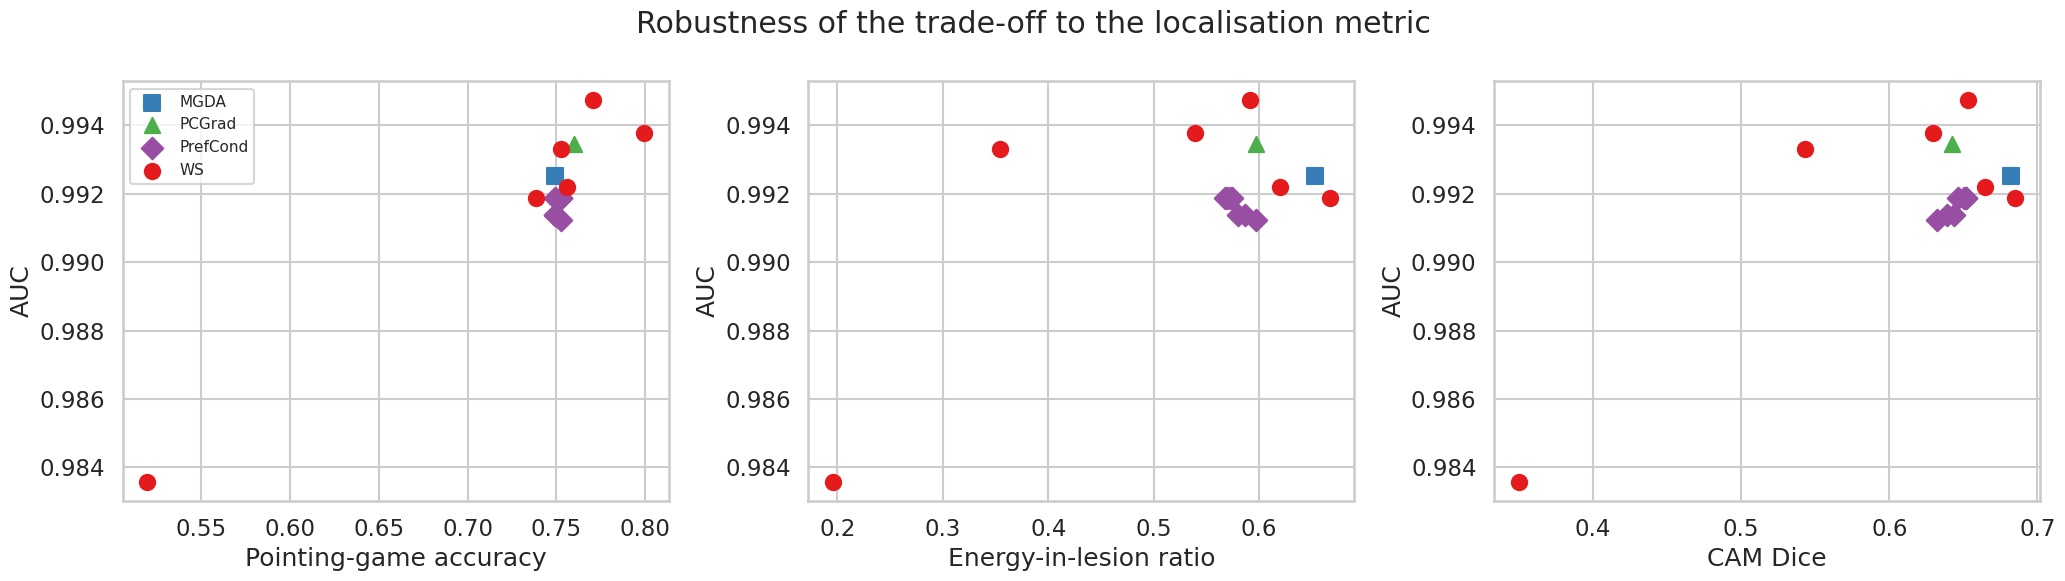

In [24]:
# ---------- 9. Pareto front: AUC vs. CAM-IoU ----------
def nondominated(P):                               # maximise both coordinates
    P = np.asarray(P); keep = []
    for i, p in enumerate(P):
        if not any((q >= p).all() and (q > p).any() for j, q in enumerate(P) if j != i): keep.append(i)
    return keep

ST = RES.groupby(['family', 'name'])[['auc', 'iou']].agg(['mean', 'std']).reset_index()
ST.columns = ['family', 'name', 'auc', 'auc_sd', 'iou', 'iou_sd']
ST = ST.fillna(0)
ST = ST[ST.family != 'Ablation'].reset_index(drop=True)
pal = dict(zip(['WS', 'MGDA', 'PCGrad', 'PrefCond'], sns.color_palette('Set1', 4)))
mk = dict(WS='o', MGDA='s', PCGrad='^', PrefCond='D')
fig, ax = plt.subplots(figsize=(10, 8))
for fam, d in ST.groupby('family'):
    ax.errorbar(d.iou, d.auc, xerr=d.iou_sd, yerr=d.auc_sd, fmt=mk[fam], color=pal[fam], ms=11, capsize=3, alpha=.9, label=fam)
    if fam in ('WS', 'PrefCond'):
        dd = d.sort_values('iou'); ax.plot(dd.iou, dd.auc, '-', color=pal[fam], alpha=.35)
for _, r in ST[ST.family == 'WS'].iterrows(): ax.annotate(r['name'].replace('ws_l', 'λ=').replace('baseline', 'λ=0'), (r.iou, r.auc), fontsize=10, xytext=(5, 5), textcoords='offset points')
nd = nondominated(ST[['iou', 'auc']].values); f_ = ST.iloc[nd].sort_values('iou')
ax.step(f_.iou, f_.auc, where='post', color='k', ls='--', lw=2, label='Global Pareto front (means)')
ax.set_xlabel('Explanation quality: CAM–lesion IoU  (↑)'); ax.set_ylabel('Diagnostic AUC  (↑)')
ax.set_title('Accuracy–interpretability Pareto front (test set, mean ± SD over seeds)'); ax.legend(loc='lower left', fontsize=12)
plt.tight_layout(); plt.savefig(f'{FIG}/02_pareto_front_auc_vs_iou.png', dpi=200); plt.show()

# secondary fronts: AUC vs pointing-game / energy / sens-spec
fig, axs = plt.subplots(1, 3, figsize=(21, 6))
for a, (xc, xl) in zip(axs, [('point', 'Pointing-game accuracy'), ('energy', 'Energy-in-lesion ratio'), ('dice', 'CAM Dice')]):
    d = MEANS[MEANS.family != 'Ablation']
    for fam, dd in d.groupby('family'): a.scatter(dd[xc], dd.auc, s=120, color=pal[fam], marker=mk[fam], label=fam)
    a.set_xlabel(xl); a.set_ylabel('AUC')
axs[0].legend(fontsize=11); plt.suptitle('Robustness of the trade-off to the localisation metric'); plt.tight_layout()
plt.savefig(f'{FIG}/03_pareto_alt_localisation_metrics.png', dpi=200); plt.show()

                      mean     std
method                            
All methods         0.2774  0.0014
MGDA                0.2723  0.0042
PCGrad              0.2542  0.0019
PrefCond (1 model)  0.2579  0.0066
WS (λ sweep)        0.2760  0.0025


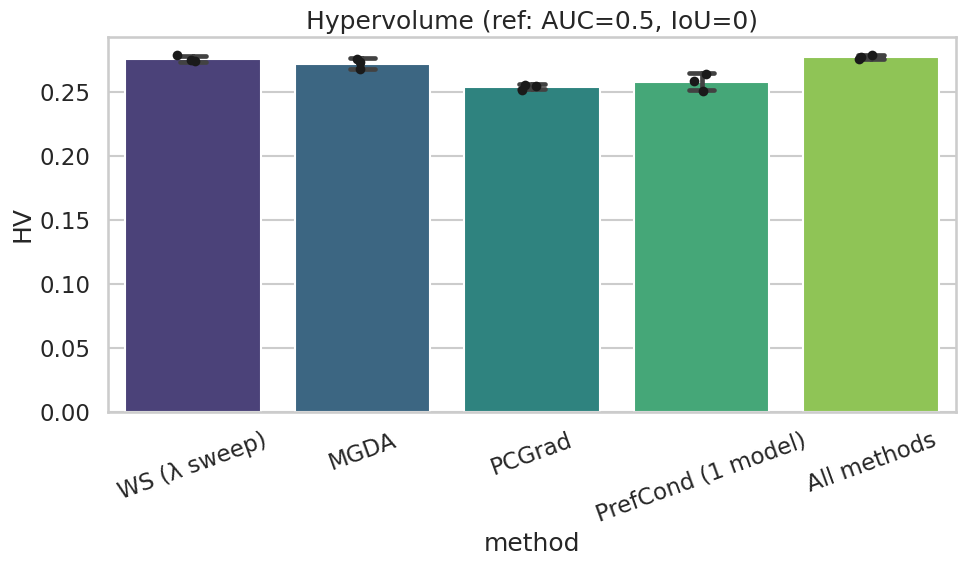

In [15]:
# ---------- 10. Hypervolume per family & seed ----------
def hv2d(points, ref=(0.5, 0.0)):
    pts = sorted([p for p in points if p[0] > ref[0] and p[1] > ref[1]], key=lambda p: -p[0]); hv, by = 0.0, ref[1]
    for x, y in pts:
        if y > by: hv += (x - ref[0]) * (y - by); by = y
    return hv
fam_names = {'WS (λ sweep)': lambda n, f: f == 'WS', 'MGDA': lambda n, f: f == 'MGDA', 'PCGrad': lambda n, f: f == 'PCGrad',
             'PrefCond (1 model)': lambda n, f: f == 'PrefCond', 'All methods': lambda n, f: f != 'Ablation'}
hv_rows = []
for seed in CFG['SEEDS']:
    d = RES[RES.seed == seed]
    for k, fn in fam_names.items():
        sel = d[[fn(n, f) for n, f in zip(d.name, d.family)]]
        hv_rows.append(dict(method=k, seed=seed, HV=hv2d(list(zip(sel.auc, sel.iou)))))
HV = pd.DataFrame(hv_rows); HV.to_csv(f'{OUT}/hypervolume.csv', index=False)
print(HV.groupby('method').HV.agg(['mean', 'std']).round(4))
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=HV, x='method', y='HV', errorbar='sd', capsize=.15, palette='viridis', ax=ax)
sns.stripplot(data=HV, x='method', y='HV', color='k', size=7, ax=ax)
ax.set_title('Hypervolume (ref: AUC=0.5, IoU=0)'); plt.xticks(rotation=20); plt.tight_layout()
plt.savefig(f'{FIG}/04_hypervolume.png', dpi=200); plt.show()

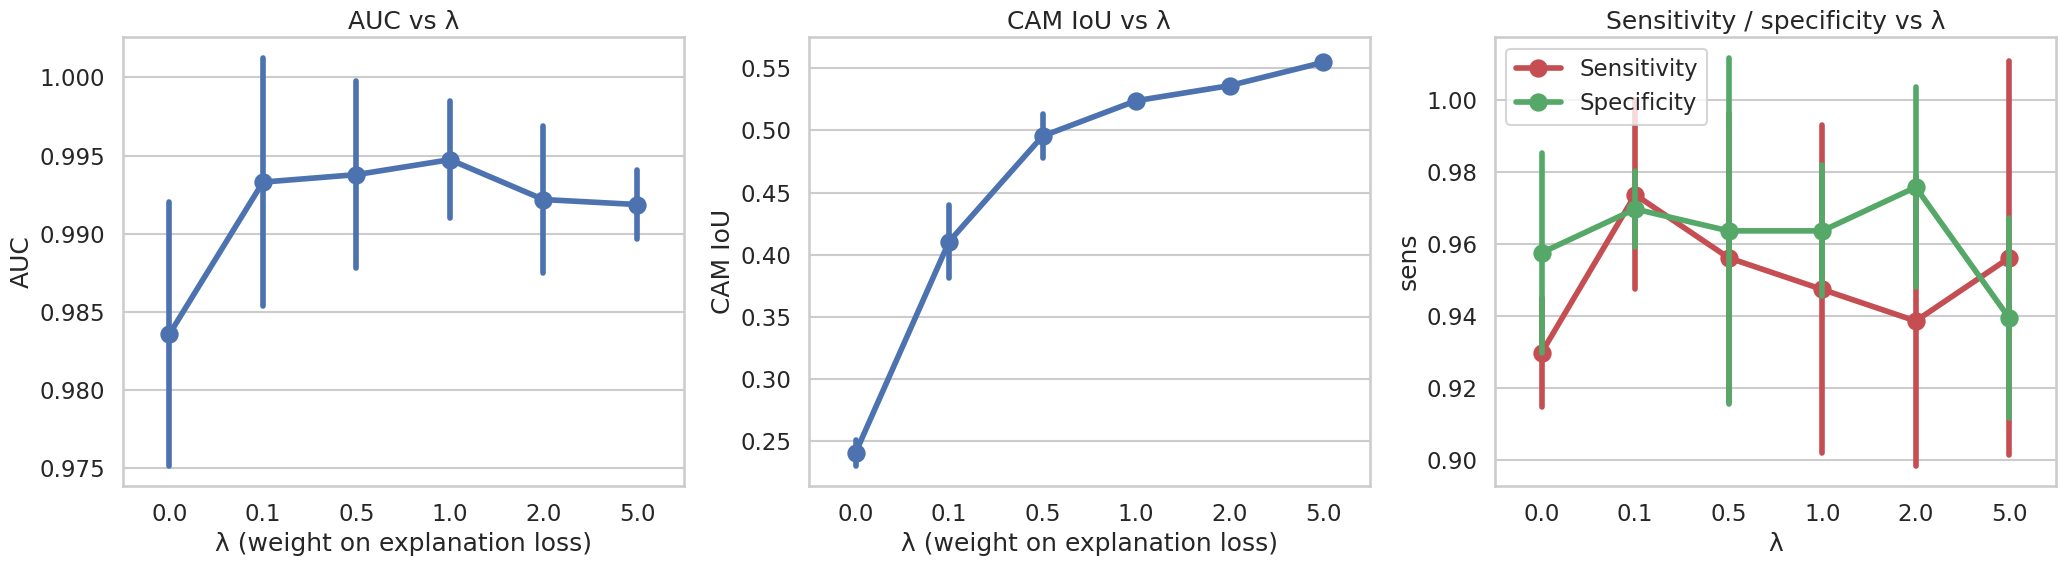

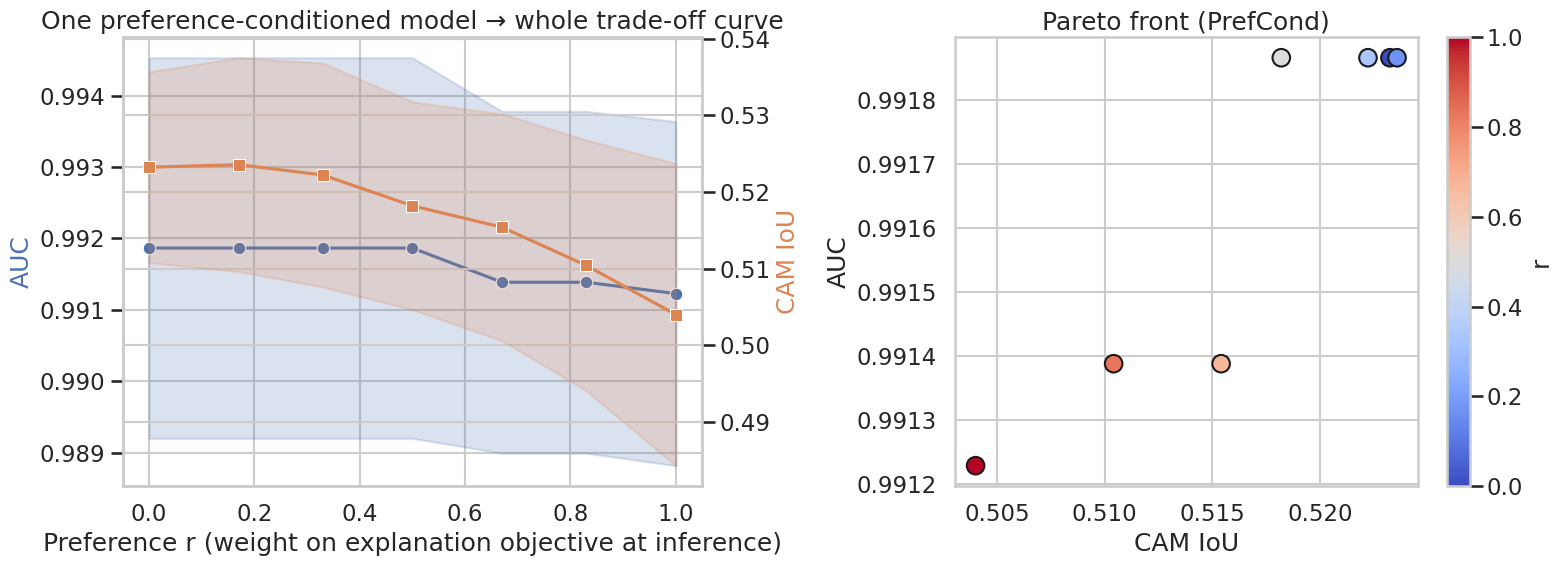

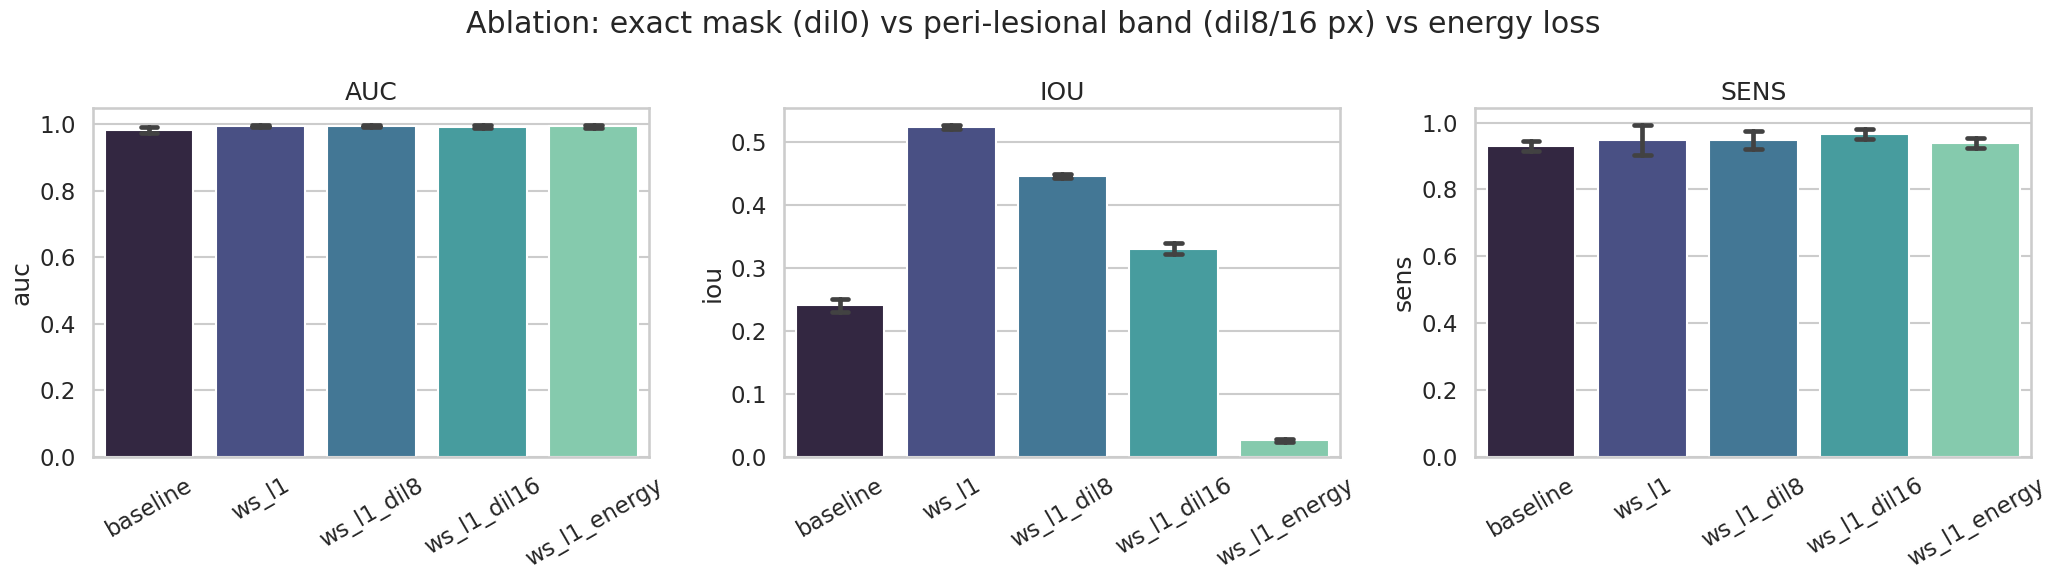

In [16]:
# ---------- 11. Lambda sweep, preference-conditioned front, ablations ----------
ws = RES[RES.name.isin(['baseline'] + [f'ws_l{l:g}' for l in CFG['LAMBDAS']])].copy()
ws['lam'] = ws.name.map(lambda n: 0.0 if n == 'baseline' else float(n.replace('ws_l', '')))
fig, ax = plt.subplots(1, 3, figsize=(21, 6))
for c, lab, a in [('auc', 'AUC', ax[0]), ('iou', 'CAM IoU', ax[1])]:
    sns.pointplot(data=ws, x='lam', y=c, errorbar='sd', ax=a, color='C0'); a.set_xlabel('λ (weight on explanation loss)'); a.set_ylabel(lab); a.set_title(f'{lab} vs λ')
sns.pointplot(data=ws, x='lam', y='sens', errorbar='sd', ax=ax[2], color='C3', label='Sensitivity')
sns.pointplot(data=ws, x='lam', y='spec', errorbar='sd', ax=ax[2], color='C2', label='Specificity'); ax[2].legend(); ax[2].set_xlabel('λ'); ax[2].set_title('Sensitivity / specificity vs λ')
plt.tight_layout(); plt.savefig(f'{FIG}/05_lambda_sweep.png', dpi=200); plt.show()

pf = RES[RES.family == 'PrefCond'].copy(); pf['r'] = pf.name.str.replace('pref_r', '').astype(float)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
a2 = ax[0].twinx(); sns.lineplot(data=pf, x='r', y='auc', marker='o', color='C0', ax=ax[0], errorbar='sd'); sns.lineplot(data=pf, x='r', y='iou', marker='s', color='C1', ax=a2, errorbar='sd')
ax[0].set_ylabel('AUC', color='C0'); a2.set_ylabel('CAM IoU', color='C1'); ax[0].set_xlabel('Preference r (weight on explanation objective at inference)'); ax[0].set_title('One preference-conditioned model → whole trade-off curve')
sc = ax[1].scatter(pf.groupby('r').iou.mean(), pf.groupby('r').auc.mean(), c=sorted(pf.r.unique()), cmap='coolwarm', s=160, edgecolor='k')
plt.colorbar(sc, ax=ax[1], label='r'); ax[1].set_xlabel('CAM IoU'); ax[1].set_ylabel('AUC'); ax[1].set_title('Pareto front (PrefCond)')
plt.tight_layout(); plt.savefig(f'{FIG}/06_preference_conditioned_front.png', dpi=200); plt.show()

ab = RES[RES.name.isin(['baseline', 'ws_l1', 'ws_l1_dil8', 'ws_l1_dil16', 'ws_l1_energy'])]
fig, ax = plt.subplots(1, 3, figsize=(21, 6)); order = ['baseline', 'ws_l1', 'ws_l1_dil8', 'ws_l1_dil16', 'ws_l1_energy']
for a, c in zip(ax, ['auc', 'iou', 'sens']):
    sns.barplot(data=ab, x='name', y=c, order=order, errorbar='sd', capsize=.15, palette='mako', ax=a); a.set_xlabel(''); a.tick_params(axis='x', rotation=30); a.set_title(c.upper())
plt.suptitle('Ablation: exact mask (dil0) vs peri-lesional band (dil8/16 px) vs energy loss'); plt.tight_layout()
plt.savefig(f'{FIG}/07_ablation_mask_dilation_loss.png', dpi=200); plt.show()

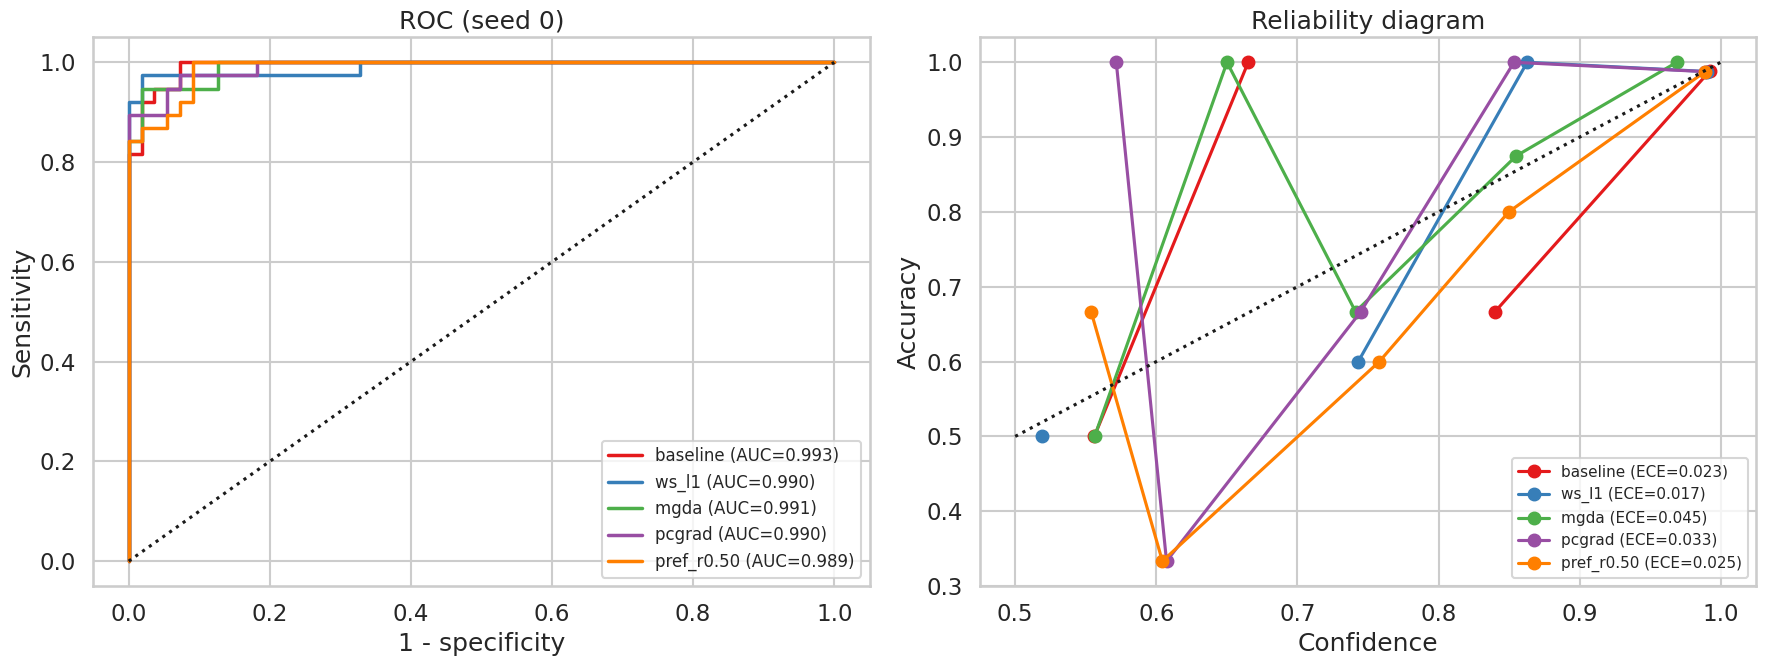

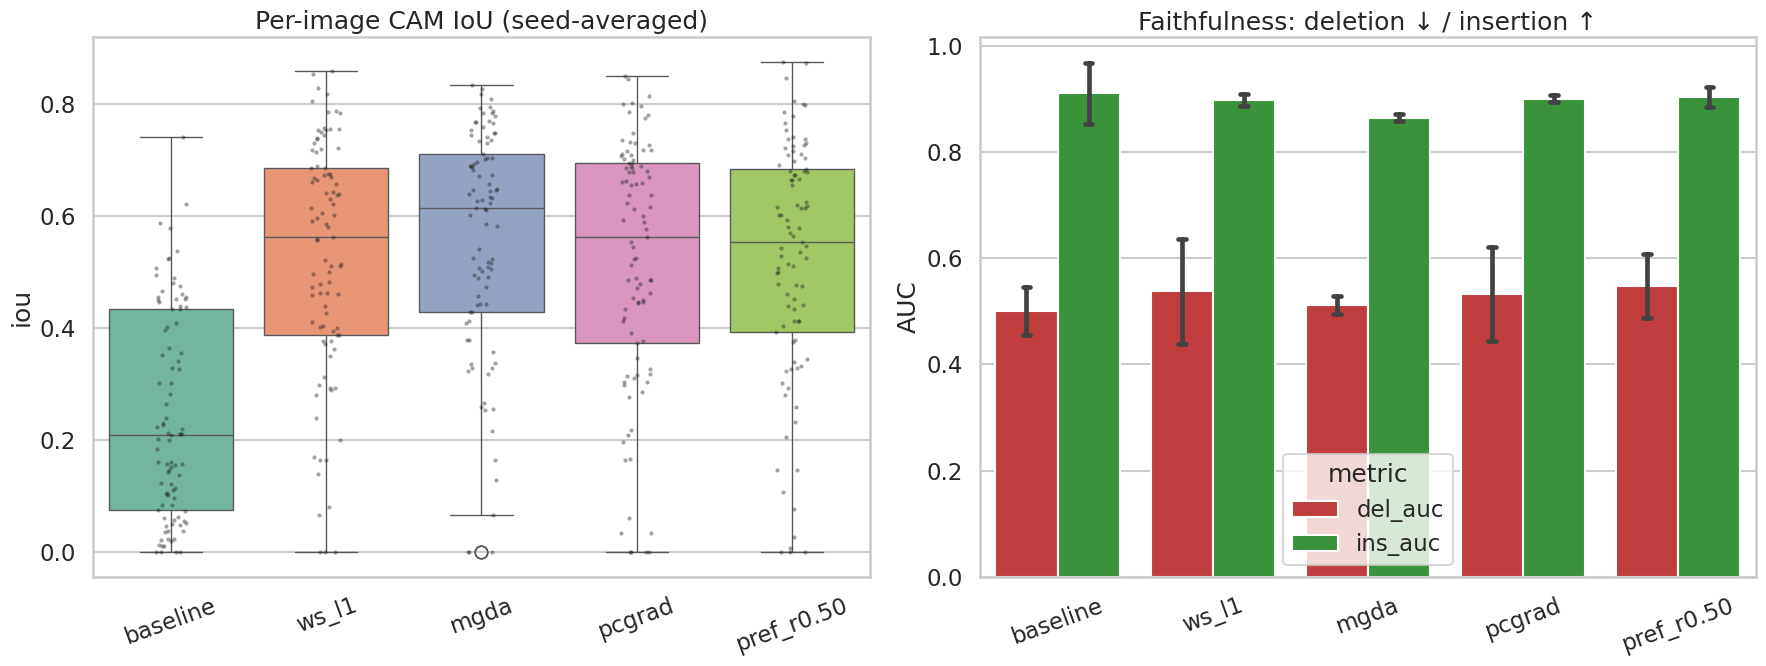

In [17]:
# ---------- 12. ROC, calibration, per-image IoU, faithfulness ----------
yte = DATA['yte'].cpu().numpy(); s0 = CFG['SEEDS'][0]; cmap5 = dict(zip(MAIN, sns.color_palette('Set1', 5)))
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for n in MAIN:
    p = PROBS[(n, s0)][:, 1]; fpr, tpr, _ = roc_curve(yte, p); ax[0].plot(fpr, tpr, lw=2.5, color=cmap5[n], label=f'{n} (AUC={roc_auc_score(yte, p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k:'); ax[0].set_xlabel('1 - specificity'); ax[0].set_ylabel('Sensitivity'); ax[0].set_title(f'ROC (seed {s0})'); ax[0].legend(fontsize=12)
for n in MAIN:
    p = PROBS[(n, s0)]; conf = p.max(1); cor = (p.argmax(1) == yte).astype(float); e, cf, ac, cn = ece_bins(conf, cor, 5)
    ax[1].plot(cf, ac, 'o-', color=cmap5[n], label=f'{n} (ECE={e:.3f})')
ax[1].plot([0.5, 1], [0.5, 1], 'k:'); ax[1].set_xlabel('Confidence'); ax[1].set_ylabel('Accuracy'); ax[1].set_title('Reliability diagram'); ax[1].legend(fontsize=11)
plt.tight_layout(); plt.savefig(f'{FIG}/08_roc_and_calibration.png', dpi=200); plt.show()

box = pd.DataFrame([dict(name=n, iou=v) for n in MAIN for v in np.mean([PER_IMG[(n, s)] for s in CFG['SEEDS']], axis=0)])
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
sns.boxplot(data=box, x='name', y='iou', palette='Set2', ax=ax[0]); sns.stripplot(data=box, x='name', y='iou', color='k', size=3, alpha=.4, ax=ax[0])
ax[0].set_title('Per-image CAM IoU (seed-averaged)'); ax[0].set_xlabel(''); ax[0].tick_params(axis='x', rotation=20)
fd = RES[RES.name.isin(MAIN)].melt(id_vars=['name', 'seed'], value_vars=['del_auc', 'ins_auc'], var_name='metric', value_name='AUC')
sns.barplot(data=fd, x='name', y='AUC', hue='metric', order=MAIN, errorbar='sd', capsize=.1, palette=['#d62728', '#2ca02c'], ax=ax[1])
ax[1].set_title('Faithfulness: deletion ↓ / insertion ↑'); ax[1].set_xlabel(''); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig(f'{FIG}/09_perimage_iou_and_faithfulness.png', dpi=200); plt.show()

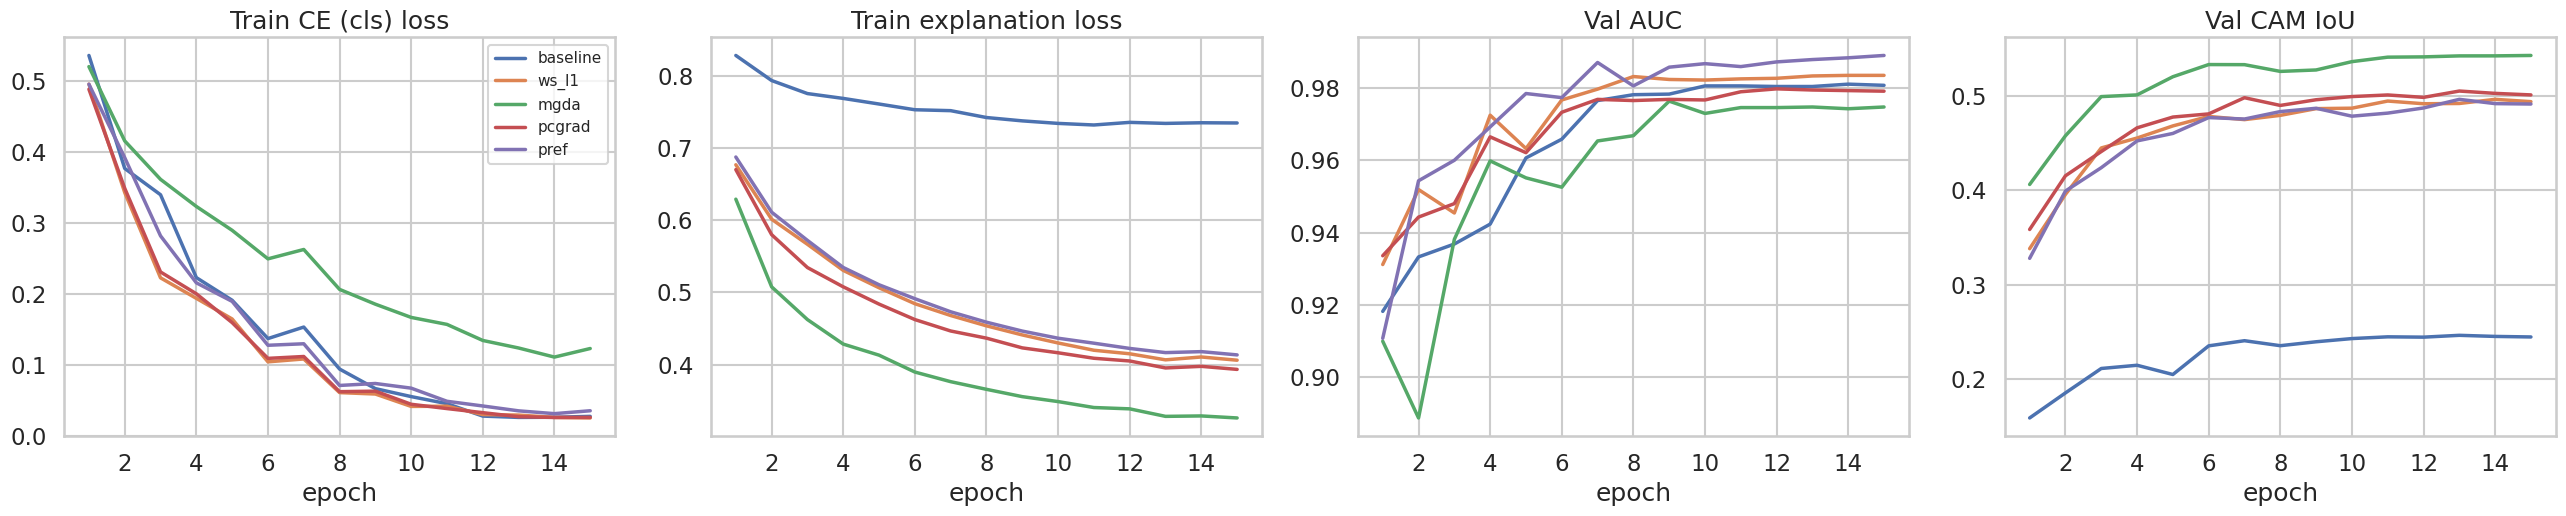

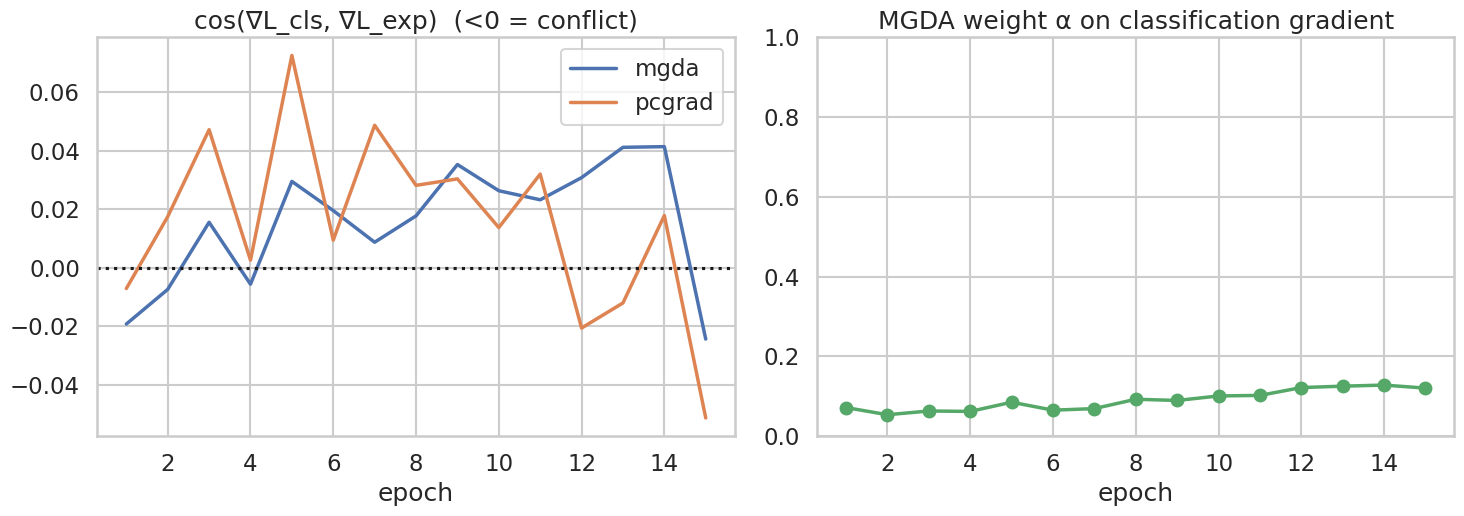

In [18]:
# ---------- 13. Training dynamics + gradient conflict ----------
fig, ax = plt.subplots(1, 4, figsize=(26, 5.5)); show = ['baseline', 'ws_l1', 'mgda', 'pcgrad', 'pref']
for n in show:
    h = pd.concat([HIST[(n, s)].assign(seed=s) for s in CFG['SEEDS']]).groupby('ep').mean()
    for a, c, t in zip(ax[:4], ['Lc', 'Le', 'val_auc', 'val_iou'], ['Train CE (cls) loss', 'Train explanation loss', 'Val AUC', 'Val CAM IoU']):
        a.plot(h.index, h[c], lw=2.5, label=n); a.set_title(t); a.set_xlabel('epoch')
ax[0].legend(fontsize=11); plt.tight_layout(); plt.savefig(f'{FIG}/10_training_curves.png', dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for n in ['mgda', 'pcgrad']:
    h = pd.concat([HIST[(n, s)] for s in CFG['SEEDS']]).groupby('ep').mean(); ax[0].plot(h.index, h.cos, lw=2.5, label=n)
ax[0].axhline(0, color='k', ls=':'); ax[0].set_title('cos(∇L_cls, ∇L_exp)  (<0 = conflict)'); ax[0].set_xlabel('epoch'); ax[0].legend()
h = pd.concat([HIST[('mgda', s)] for s in CFG['SEEDS']]).groupby('ep').mean(); ax[1].plot(h.index, h.alpha, 'g-o', lw=2.5)
ax[1].set_title('MGDA weight α on classification gradient'); ax[1].set_xlabel('epoch'); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(f'{FIG}/11_gradient_conflict.png', dpi=200); plt.show()

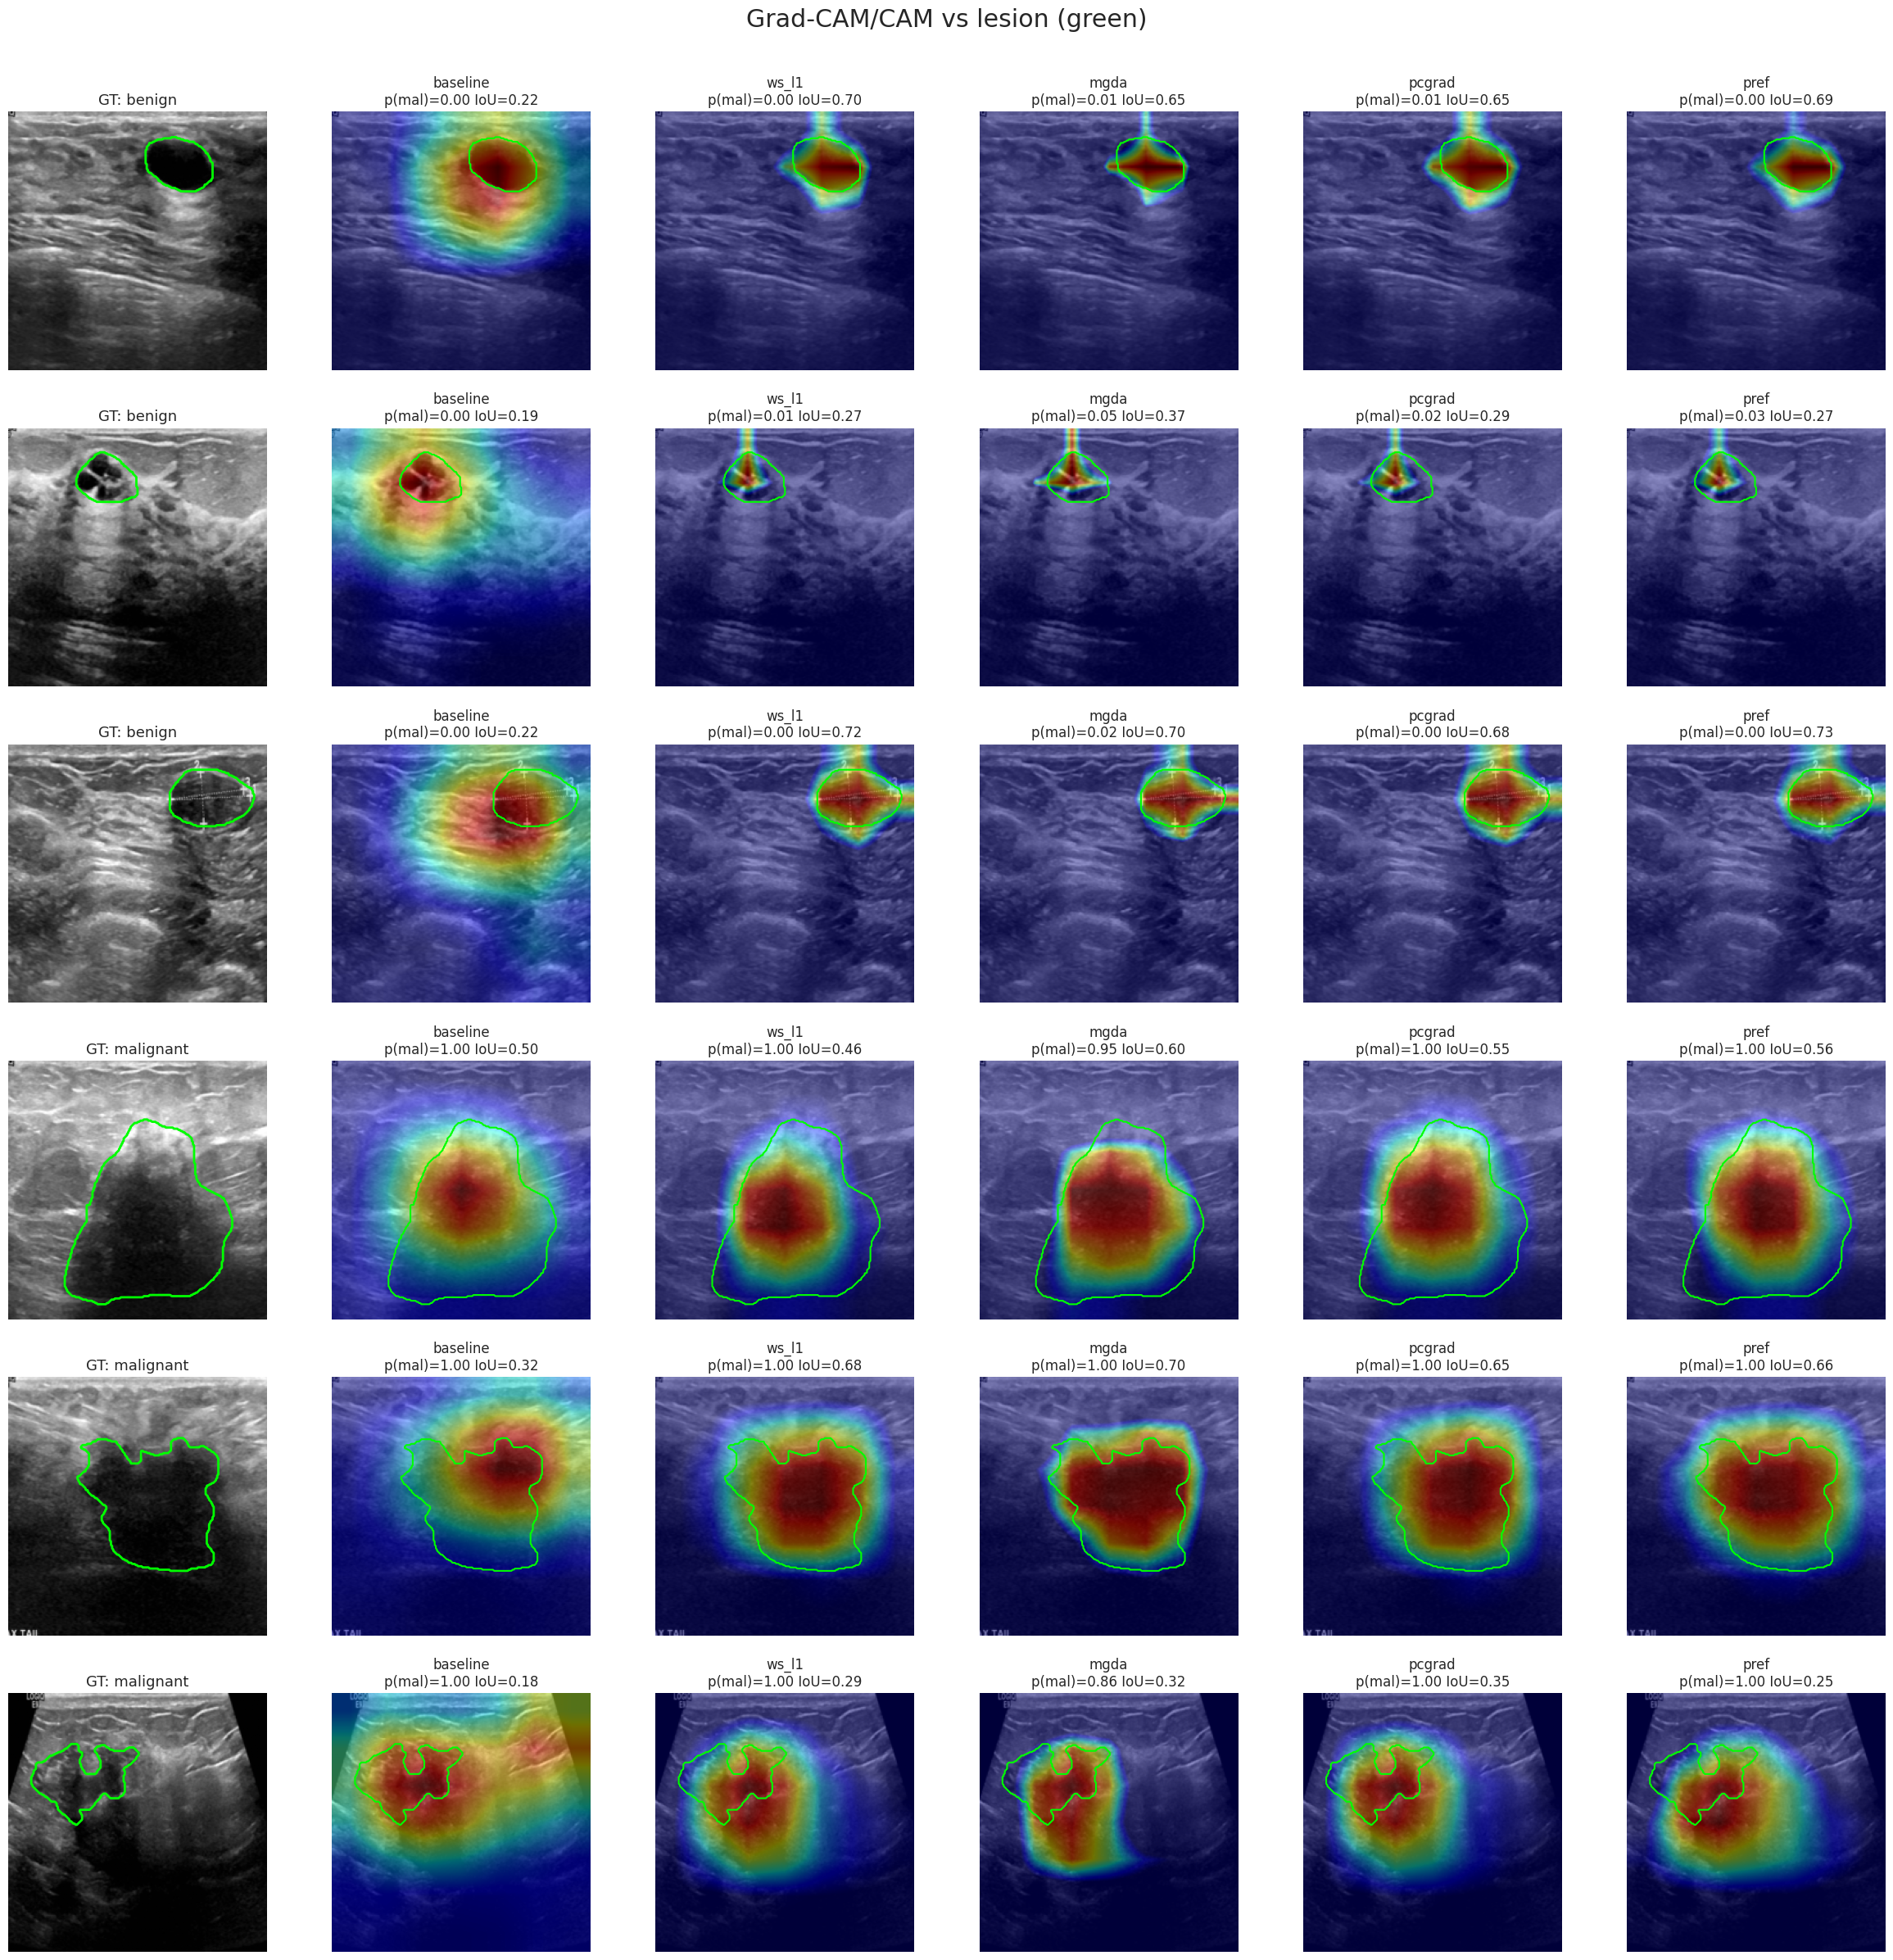

In [19]:
# ---------- 14. Qualitative CAM overlays (seed-0 models) ----------
te_y = DATA['yte'].cpu().numpy()
pick = list(np.where(te_y == 0)[0][:3]) + list(np.where(te_y == 1)[0][:3])
cols_ = ['baseline', 'ws_l1', 'mgda', 'pcgrad', 'pref']
CAMS = {}
for n in cols_:
    pr = [0.5, 0.5] if n == 'pref' else None
    p_, c_ = predict(MODELS[n], DATA['Xte'], pr); CAMS[n] = (p_.cpu().numpy(), c_.cpu().numpy())
fig, ax = plt.subplots(len(pick), len(cols_) + 1, figsize=(4 * (len(cols_) + 1), 4 * len(pick)))
for r, i in enumerate(pick):
    img, msk = DATA['Xte'][i, 0].cpu().numpy(), DATA['Mte'][i, 0].cpu().numpy()
    ax[r, 0].imshow(img, cmap='gray'); ax[r, 0].contour(msk, [0.5], colors='lime', linewidths=2); ax[r, 0].set_title(f'GT: {["benign", "malignant"][te_y[i]]}', fontsize=13)
    for c, n in enumerate(cols_):
        pr_, cm = CAMS[n]; ax[r, c + 1].imshow(img, cmap='gray'); ax[r, c + 1].imshow(cm[i, 0], cmap='jet', alpha=.45, vmin=0, vmax=1)
        ax[r, c + 1].contour(msk, [0.5], colors='lime', linewidths=1.5)
        iou = ((cm[i, 0] >= .5) & (msk > .5)).sum() / max(((cm[i, 0] >= .5) | (msk > .5)).sum(), 1)
        ax[r, c + 1].set_title(f'{n}\np(mal)={pr_[i, 1]:.2f} IoU={iou:.2f}', fontsize=12)
for a in ax.ravel(): a.axis('off')
plt.suptitle('Grad-CAM/CAM vs lesion (green)', y=1.0); plt.tight_layout(); plt.savefig(f'{FIG}/12_qualitative_cams.png', dpi=150); plt.show()

In [20]:
# ---------- 15. Statistics: paired Wilcoxon on per-image IoU, bootstrap AUC CIs, sanity checks ----------
base = np.mean([PER_IMG[('baseline', s)] for s in CFG['SEEDS']], axis=0); st = []
for n in MAIN[1:]:
    v = np.mean([PER_IMG[(n, s)] for s in CFG['SEEDS']], axis=0)
    st.append(dict(method=n, mean_IoU_gain=float((v - base).mean()), wilcoxon_p=float(wilcoxon(v, base).pvalue)))
ST_TEST = pd.DataFrame(st); ST_TEST.to_csv(f'{OUT}/wilcoxon_iou_vs_baseline.csv', index=False); display(ST_TEST)

rng = np.random.default_rng(0); ci = []
for n in MAIN:
    p = PROBS[(n, s0)][:, 1]; bs = []
    for _ in range(1000):
        b = rng.integers(0, len(yte), len(yte))
        if len(np.unique(yte[b])) == 2: bs.append(roc_auc_score(yte[b], p[b]))
    ci.append(dict(method=n, AUC=roc_auc_score(yte, p), lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5)))
CI = pd.DataFrame(ci); CI.to_csv(f'{OUT}/auc_bootstrap_ci.csv', index=False); display(CI.round(3))

san = []
for n in MAIN:
    pr = [0.5, 0.5] if n == 'pref_r0.50' else None; key = 'pref' if n == 'pref_r0.50' else n
    san.append(dict(method=n, mean_abs_spearman_after_randomisation=randomization_check(MODELS[key], DATA['Xte'], pr)))
SAN = pd.DataFrame(san); SAN.to_csv(f'{OUT}/sanity_randomisation.csv', index=False); display(SAN.round(3))   # lower = CAM depends on learned weights (passes)

,method,mean_IoU_gain,wilcoxon_p
0,ws_l1,0.283214,1.843548e-15
1,mgda,0.312283,1.068482e-15
2,pcgrad,0.274452,4.209248e-15
3,pref_r0.50,0.277591,1.254992e-15


,method,AUC,lo,hi
0,baseline,0.993,0.981,1.000
1,ws_l1,0.990,0.968,1.000
2,mgda,0.991,0.976,1.000
3,pcgrad,0.990,0.975,1.000
4,pref_r0.50,0.989,0.971,0.999


,method,mean_abs_spearman_after_randomisation
0,baseline,0.214
1,ws_l1,0.277
2,mgda,0.235
3,pcgrad,0.154
4,pref_r0.50,0.172


,lam,lr,dil,val_auc,val_iou,test_auc,test_iou,front
8,0.4147,0.0005,6,0.9795,0.4028,0.9885,0.4236,True
11,0.0371,0.0005,11,0.9829,0.3029,0.9952,0.3313,True
15,7.6417,0.0001,3,0.9669,0.4958,0.9871,0.4780,True
17,0.7609,0.0005,3,0.9790,0.4720,0.9780,0.5070,True


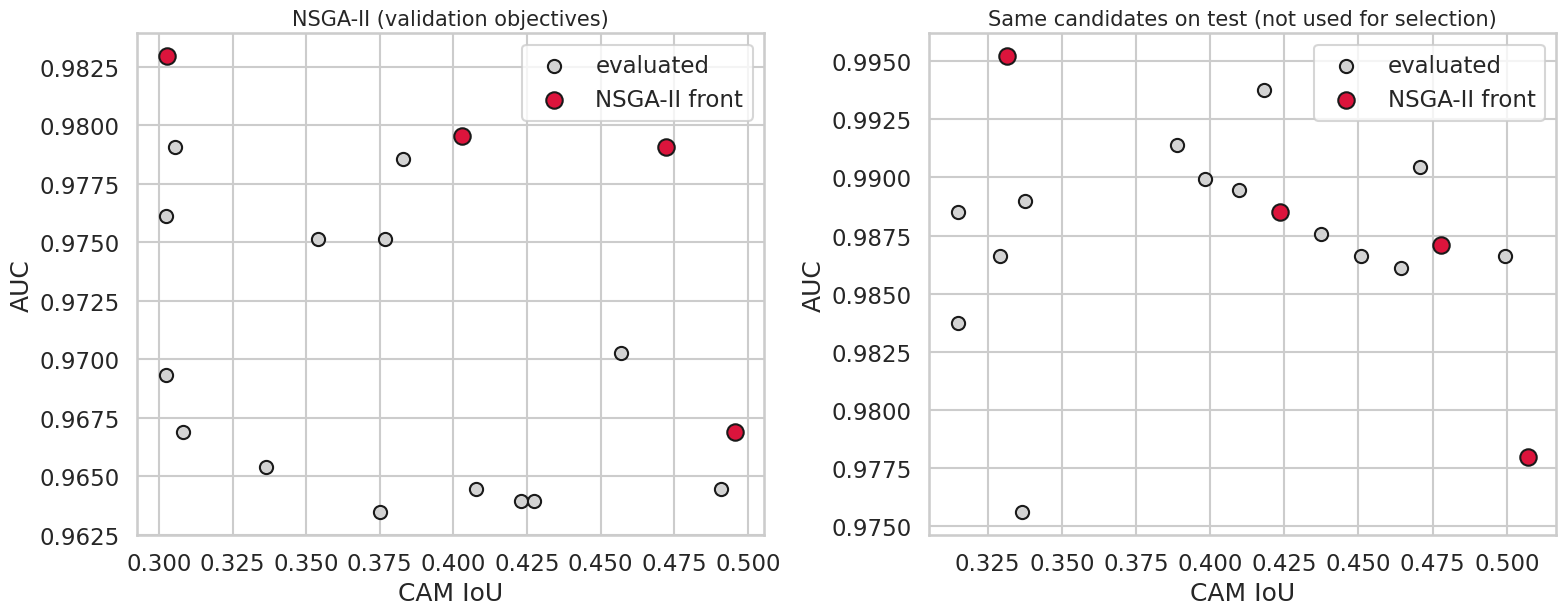

In [21]:
# ---------- 16. NSGA-II: hyper-parameter-level multi-objective search (lambda, lr, dilation) ----------
if CFG['RUN_NSGA2']:
    from pymoo.algorithms.moo.nsga2 import NSGA2
    from pymoo.core.problem import ElementwiseProblem
    from pymoo.optimize import minimize
    NSGA_LOG = []
    class HPO(ElementwiseProblem):
        def __init__(self): super().__init__(n_var=3, n_obj=2, xl=np.array([-1.5, -4.5, 0.0]), xu=np.array([1.0, -3.0, 20.0]))
        def _evaluate(self, x, out, *a, **k):
            lam, lr, dil = 10 ** x[0], 10 ** x[1], int(round(x[2]))
            m, h = train_run('ws', lam, dil, 'dice', 0, DATA, epochs=CFG['NSGA_EPOCHS'], lr=lr)
            va_auc, va_iou = h.val_auc.iloc[-1], h.val_iou.iloc[-1]          # selection uses VALIDATION only
            p, c = predict(m, DATA['Xte']); tm, _ = compute_metrics(p, DATA['yte'], c, DATA['Mte'])
            NSGA_LOG.append(dict(lam=lam, lr=lr, dil=dil, val_auc=va_auc, val_iou=va_iou, test_auc=tm['auc'], test_iou=tm['iou']))
            out['F'] = [1 - va_auc, 1 - va_iou]; del m; torch.cuda.empty_cache()
    res = minimize(HPO(), NSGA2(pop_size=CFG['NSGA_POP']), ('n_gen', CFG['NSGA_GEN']), seed=1, verbose=False)
    NG = pd.DataFrame(NSGA_LOG); NG['front'] = False
    for f_row in res.F:
        NG.loc[((NG.val_auc - (1 - f_row[0])).abs() < 1e-9) & ((NG.val_iou - (1 - f_row[1])).abs() < 1e-9), 'front'] = True
    NG.to_csv(f'{OUT}/nsga2_search_log.csv', index=False); display(NG[NG.front].round(4))
    fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
    for a, (xa, ya, t) in zip(ax, [('val_iou', 'val_auc', 'NSGA-II (validation objectives)'), ('test_iou', 'test_auc', 'Same candidates on test (not used for selection)')]):
        a.scatter(NG[xa], NG[ya], c='lightgray', s=90, edgecolor='k', label='evaluated'); a.scatter(NG[NG.front][xa], NG[NG.front][ya], c='crimson', s=140, edgecolor='k', label='NSGA-II front')
        a.set_xlabel('CAM IoU'); a.set_ylabel('AUC'); a.set_title(t, fontsize=15); a.legend()
    plt.tight_layout(); plt.savefig(f'{FIG}/13_nsga2_front.png', dpi=200); plt.show()

[confounder seed 0] baseline done
[confounder seed 0] ws_l1 done
[confounder seed 0] ws_l5 done
[confounder seed 0] mgda done
[confounder seed 1] baseline done
[confounder seed 1] ws_l1 done
[confounder seed 1] ws_l5 done
[confounder seed 1] mgda done
[confounder seed 2] baseline done
[confounder seed 2] ws_l1 done
[confounder seed 2] ws_l5 done
[confounder seed 2] mgda done


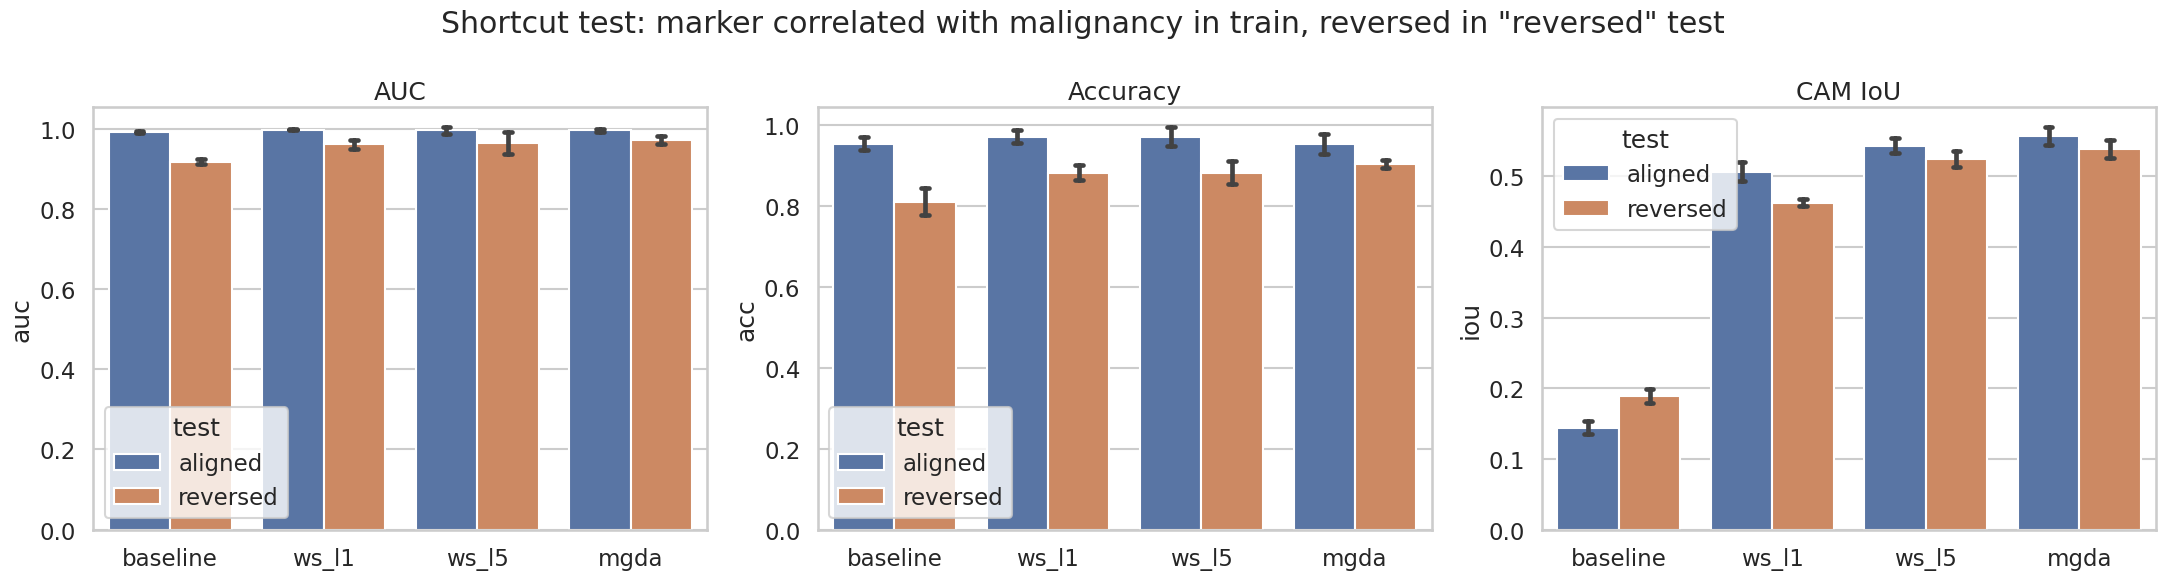

auc    acc    iou
method   test                         
baseline aligned   0.990  0.953  0.144
         reversed  0.917  0.810  0.189
mgda     aligned   0.996  0.953  0.557
         reversed  0.972  0.903  0.539
ws_l1    aligned   0.997  0.971  0.507
         reversed  0.961  0.882  0.463
ws_l5    aligned   0.995  0.971  0.543
         reversed  0.963  0.882  0.525

In [22]:
# ---------- 17. Shortcut-learning experiment: synthetic confounder (a bright "caliper" marker) ----------
# Train/val: marker appears with 90% probability on MALIGNANT images. Test-aligned: same rule.
# Test-reversed: marker appears with 90% probability on BENIGN images -> a shortcut-reliant model collapses.
if CFG['RUN_CONFOUNDER']:
    def add_marker(X, flag):
        X = X.clone(); X[flag, :, 8:28, 8:28] = 255; return X
    def marker_flags(y, p_mal, seed):
        g = torch.Generator().manual_seed(seed); u = torch.rand(len(y), generator=g)
        return torch.where(y == 1, u < p_mal, u < (1 - p_mal))
    yv = y_all.clone(); Xc = X_all.clone()
    flag = torch.zeros(N, dtype=torch.bool)
    for ii, ps, sd in [(i_tr, .9, 1), (i_va, .9, 2), (i_te, .9, 3)]: flag[ii] = marker_flags(y_all[ii], ps, sd)
    Xc = add_marker(X_all, flag); DATA_C = make_data(Xc, M_all, y_all)
    Xrev = X_all.clone(); fr_ = marker_flags(y_all[i_te], 0.1, 3)                 # reversed correlation on test
    Xrev[i_te] = add_marker(X_all[i_te], fr_); Xte_rev = Xrev[i_te].to(DEVICE)
    cf_rows = []
    for seed in CFG['SEEDS']:
        for name, method, lam in [('baseline', 'ws', 0.0), ('ws_l1', 'ws', 1.0), ('ws_l5', 'ws', 5.0), ('mgda', 'mgda', 1)]:
            m, _ = train_run(method, lam, 0, 'dice', seed, DATA_C)
            for split, Xs in [('aligned', DATA_C['Xte']), ('reversed', Xte_rev)]:
                p, c = predict(m, Xs); mm, _ = compute_metrics(p, DATA_C['yte'], c, DATA_C['Mte'])
                cf_rows.append(dict(method=name, seed=seed, test=split, auc=mm['auc'], acc=mm['acc'], iou=mm['iou']))
            print(f'[confounder seed {seed}] {name} done'); del m; torch.cuda.empty_cache()
    CF = pd.DataFrame(cf_rows); CF.to_csv(f'{OUT}/confounder_experiment.csv', index=False)
    fig, ax = plt.subplots(1, 3, figsize=(22, 6))
    for a, c, t in zip(ax, ['auc', 'acc', 'iou'], ['AUC', 'Accuracy', 'CAM IoU']):
        sns.barplot(data=CF, x='method', y=c, hue='test', errorbar='sd', capsize=.1, palette=['#4c72b0', '#dd8452'], ax=a); a.set_title(t); a.set_xlabel('')
    plt.suptitle('Shortcut test: marker correlated with malignancy in train, reversed in "reversed" test'); plt.tight_layout()
    plt.savefig(f'{FIG}/14_confounder_shortcut_test.png', dpi=200); plt.show()
    display(CF.groupby(['method', 'test'])[['auc', 'acc', 'iou']].mean().round(3))

In [23]:
# ---------- 18. Automatic findings + export ----------
M_ = MEANS[MEANS.family != 'Ablation']
b_auc, b_iou = M_.loc[M_.auc.idxmax()], M_.loc[M_.iou.idxmax()]
print(f"Highest AUC : {b_auc['name']}  (AUC={b_auc['auc']:.3f}, IoU={b_auc['iou']:.3f})")
print(f"Highest IoU : {b_iou['name']}  (AUC={b_iou['auc']:.3f}, IoU={b_iou['iou']:.3f})")

hv_mean = HV.groupby('method').HV.mean().drop('All methods')
print(f"Best hypervolume family: {hv_mean.idxmax()} (HV={float(hv_mean.max()):.4f})")
print('\nHypervolume by family:\n', hv_mean.round(4).to_string())

base_ = M_[M_.name == 'baseline'].iloc[0]
print(f"\nBaseline: AUC={base_['auc']:.3f}, IoU={base_['iou']:.3f}")

print('\nTables: ', sorted(os.listdir(OUT)), '\nFigures:', sorted(os.listdir(FIG)))
shutil.make_archive('bus_multiobjective_results', 'zip', OUT)
try:
    from google.colab import files
    files.download('bus_multiobjective_results.zip')
except Exception as e:
    print('Download manually:', e)

Highest AUC : ws_l1  (AUC=0.995, IoU=0.524)
Highest IoU : ws_l5  (AUC=0.992, IoU=0.555)
Best hypervolume family: WS (λ sweep) (HV=0.2760)

Hypervolume by family:
 method
MGDA                  0.2723
PCGrad                0.2542
PrefCond (1 model)    0.2579
WS (λ sweep)          0.2760

Baseline: AUC=0.984, IoU=0.241

Tables:  ['all_runs_test_metrics.csv', 'auc_bootstrap_ci.csv', 'confounder_experiment.csv', 'figs', 'hypervolume.csv', 'nsga2_search_log.csv', 'sanity_randomisation.csv', 'summary_mean_std.csv', 'wilcoxon_iou_vs_baseline.csv'] 
Figures: ['00_dataset_samples.png', '01_metrics_heatmap.png', '02_pareto_front_auc_vs_iou.png', '03_pareto_alt_localisation_metrics.png', '04_hypervolume.png', '05_lambda_sweep.png', '06_preference_conditioned_front.png', '07_ablation_mask_dilation_loss.png', '08_roc_and_calibration.png', '09_perimage_iou_and_faithfulness.png', '10_training_curves.png', '11_gradient_conflict.png', '12_qualitative_cams.png', '13_nsga2_front.png', '14_confounder_short

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>